# Data analysis on-targets

## Read in inputs

### Read in libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras import backend as K
from ML_helper_functions import PearsonCorr, OneHot, OneHotSeries, preprocess_RNA, train_full_model, pearson_correlation, spearman_correlation, MSE, MAE, Transformer, PositionalEmbedding, preprocess_RNA_embedding, RNA_tokenizer

2026-01-29 09:42:00.301683: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-29 09:42:00.324478: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-01-29 09:42:00.324503: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-01-29 09:42:00.325212: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-01-29 09:42:00.329638: I tensorflow/core/platform/cpu_feature_guar

### Read in the models
Each model has a identifier and a name. The name is supposed to reflect the model architecture.

In [2]:
# Import parameters #

base_folder = "RESULT/"
palette="viridis"

dataset = pd.read_excel('ML_overview_REPEAT_PWT.xlsx')

models = dataset['Name'].to_list()
alternative_naming = dataset['Model'].to_list()

In [3]:
# Check the naming #

for model, alt in zip(models, alternative_naming):
    print(model + " \t => \t" + alt)

MODEL_A 	 => 	Cap-3
MODEL_A5 	 => 	Cap-5
MODEL_B 	 => 	CmP-3
MODEL_B5 	 => 	CmP-5
MODEL_C 	 => 	CCaP-3
MODEL_C5 	 => 	CCaP-5
MODEL_D 	 => 	2CaP-3
MODEL_D1 	 => 	2CaP-1
MODEL_D2 	 => 	2CaP-2
MODEL_D4 	 => 	2CaP-4
MODEL_D5 	 => 	2CaP-5
MODEL_E 	 => 	CaPr-3
MODEL_E5 	 => 	CaPr-5
MODEL_F 	 => 	CCmP-3
MODEL_F5 	 => 	CCmP-5
MODEL_G 	 => 	2CmP-3
MODEL_G1 	 => 	2CmP-1
MODEL_G2 	 => 	2CmP-2
MODEL_G4 	 => 	2CmP-4
MODEL_G5 	 => 	2CmP-5
MODEL_H 	 => 	CmPr-3
MODEL_H5 	 => 	CmPr-5
MODEL_I 	 => 	Base
MODEL_J 	 => 	BiRd
MODEL_K 	 => 	2BiRd
MODEL_L 	 => 	BiRdr
MODEL_M 	 => 	2BiRdr
MODEL_N 	 => 	3Cap-3
MODEL_N1 	 => 	3Cap-1
MODEL_N2 	 => 	3Cap-2
MODEL_N4 	 => 	3Cap-4
MODEL_O 	 => 	3CmP-3
MODEL_O1 	 => 	3CmP-1
MODEL_O2 	 => 	3CmP-2
MODEL_O4 	 => 	3CmP-4
MODEL_Q 	 => 	BiR
MODEL_R 	 => 	2BiR
MODEL_S 	 => 	BiRr
MODEL_T 	 => 	2BiRr
MODEL_U 	 => 	3BiR


## Create helper functions

In [4]:
# Helper functions #

def create_fig(df, x, y, add_fraction=0.05):
    addition = add_fraction*max(df[y])
    plt.figure(figsize = (20, 10), dpi = 200)    
    fg1 = sns.barplot(data=df, x=x, y=y, palette=palette, hue=x)
    fg1.set(ylim=(max(min(df[y])-addition, 0), max(df[y])+addition))   
    plt.xticks(rotation=90)
    plt.show()

    
def image_multiple_models(base_folder, models, alternative_naming, palette, output_name=None):    
    ### PEARSON CORRELATION TEST DATA ###
    ## Get the model test results ##
    # Lists for the results #
    names = []
    corr_mse_val = []
    corr_pearson_val = []
    corr_spearman_val = []
    corr_mse_test = []
    corr_pearson_test = []
    corr_spearman_test = []
    size_model = []
    
    for count, model in enumerate(models):
        # Get the filename #
        filepath = base_folder+model+"/model_" + model[6:]+"_properties.csv"
        # Read the data in #
        data_in = pd.read_csv(filepath, sep="\t", index_col=0)
        
        # Save the data #
        names.append(alternative_naming[count])
        corr_mse_val.append(data_in.loc['validation mse','value'])
        corr_pearson_val.append(data_in.loc['validation pearson','value'])
        corr_spearman_val.append(data_in.loc['validation spearman','value'])
        corr_mse_test.append(data_in.loc['test mse','value'])
        corr_pearson_test.append(data_in.loc['test pearson','value'])
        corr_spearman_test.append(data_in.loc['test spearman','value'])
        size_model.append(data_in.loc['size','value'])
        
    # Create a dataframe #
    df = pd.DataFrame({"Model":names, "Size": size_model,
                       "MSE correlation - validation":corr_mse_val, 
                       "MSE correlation - testing":corr_mse_test,
                       "Pearson correlation - validation":corr_pearson_val, 
                       "Pearson correlation - testing":corr_pearson_test, 
                       "Spearman correlation - validation":corr_spearman_val, 
                       "Spearman correlation - testing":corr_spearman_test, })
    df.dropna(axis=0, how='any', inplace=True)
    
    # Sort the dataframe #
    df.sort_values(by="MSE correlation - validation", inplace=True, ignore_index=True)
    cols = df.columns[1:]  # everything except "Model"
    df[cols] = df[cols].apply(lambda s: pd.to_numeric(s, errors="coerce"))
    #df.iloc[:,1:] = df.iloc[:,1:].astype(float)
    
    ## Visualize the results ##      
    # MSE validation #
    create_fig(df, x="Model", y="MSE correlation - validation")
    # Pearson validation #
    create_fig(df, x="Model", y="Pearson correlation - validation")
    # Spearman validation #
    create_fig(df, x="Model", y="Spearman correlation - validation")
    # MSE test #
    create_fig(df, x="Model", y="MSE correlation - testing")
    # Pearson test #
    create_fig(df, x="Model", y="Pearson correlation - testing")
    # Spearman validation #
    create_fig(df, x="Model", y="Spearman correlation - testing")
    # model size #
    create_fig(df, x="Model", y="Size")
    
    if output_name is not None:
        df.to_excel(output_name)
    
    return list(df['Model'])


def test_result_actual_model(base_folder, models, alternative_naming, palette, sorted_names, X_test, y_test, output_name=None):
    ### TEST RESULTS OF THE ACTUAL MODELS ###
    ## Get the model test results ##
    # Lists for the results #
    names = []
    results_mse = []
    results_pearson = []
    results_spearman = []

    for count, model_name in enumerate(models):
        # Get the filename #
        filepath = base_folder+model_name+"/model_" + model_name[6:]+".tf"
        
        # Load in the model #
        objects = {"OneHotSeries":  OneHotSeries, "PearsonCorr": PearsonCorr}
        if model_name=="MODEL_I":
            objects = {"OneHot":  OneHot, "PearsonCorr": PearsonCorr}
        model = tf.keras.models.load_model(filepath, custom_objects=objects)
        
        # Get the model performance #        
        y_pred = model.predict(X_test, verbose=0)
        y_pred = y_pred.reshape((-1,))
    
        names.append(alternative_naming[count])
        results_mse.append(MSE(y_test, y_pred))
        results_pearson.append(pearson_correlation(y_test, y_pred))
        results_spearman.append(spearman_correlation(y_test, y_pred))
    
    # Create a dataframe #
    df = pd.DataFrame({"Model":names, "MSE":results_mse, "Pearson":results_pearson, "Spearman":results_spearman})
    sort_dict = {name: num for name, num in zip(sorted_names, range(len(sorted_names)))}
    df.sort_values(by=["Model"], key=lambda x: x.map(sort_dict), inplace=True)
    
    ## Visualize the results in bar plot form ##
    # MSE #
    create_fig(df, x="Model", y="MSE")
    # Pearson #
    create_fig(df, x="Model", y="Pearson")
    # Spearman #
    create_fig(df, x="Model", y="Spearman")
    
    if output_name is not None:
        df.to_excel(output_name)

    
def prediction_scatter(base_folder, model_name, alt_name, X_1, y_1, X_2, y_2, title_1="Training set", title_2="Testing set", palette=None, output_name=None):
    filepath = base_folder+model_name+"/model_" + model_name[6:]+".tf"
        
    # Load in the model #
    objects = {"OneHotSeries":  OneHotSeries, "PearsonCorr": PearsonCorr}    
    model = tf.keras.models.load_model(filepath, custom_objects=objects)
        
    # Get the model performance #
    y_pred_1 = model.predict(X_1, verbose=0)
    y_pred_1 = y_pred_1.reshape((-1,))
    y_pred_2 = model.predict(X_2, verbose=0)
    y_pred_2 = y_pred_2.reshape((-1,))
    
    mae_1 = abs(y_pred_1 - y_1)
    mae_2 = abs(y_pred_2 - y_2)
    
    df = pd.DataFrame({'y_true': np.concatenate([y_1, y_2]), 'y_pred': np.concatenate([y_pred_1, y_pred_2]), 
                       'mae': np.concatenate([mae_1, mae_2]), 
                       'dataset': np.concatenate([[title_1]*len(y_1), [title_2]*len(y_2)])})
    
    plt.figure(figsize = (20, 10), dpi = 200)
    fg = sns.scatterplot(data=df, x='y_true', y='y_pred', hue='dataset', style='dataset', palette=palette)
    plt.xlabel('True value')
    plt.ylabel('Predicted value')
    plt.title(alt_name)
    plt.plot(np.linspace(0, 1, 50), np.linspace(0, 1, 50), c='black', ls='dashed')
    plt.show()
    
    plt.figure(figsize = (20, 10), dpi = 200)
    fg = sns.scatterplot(data=df, x='y_true', y='mae', hue='dataset', style='dataset', palette=palette)
    plt.xlabel('True value')
    plt.ylabel('Absolute error')
    plt.title(alt_name)
    plt.axhline(0, c='black', ls='dashed')
    plt.show()
    
    if output_name is not None:
        df.to_excel(output_name)

## Data analysis

### Test and validation performance


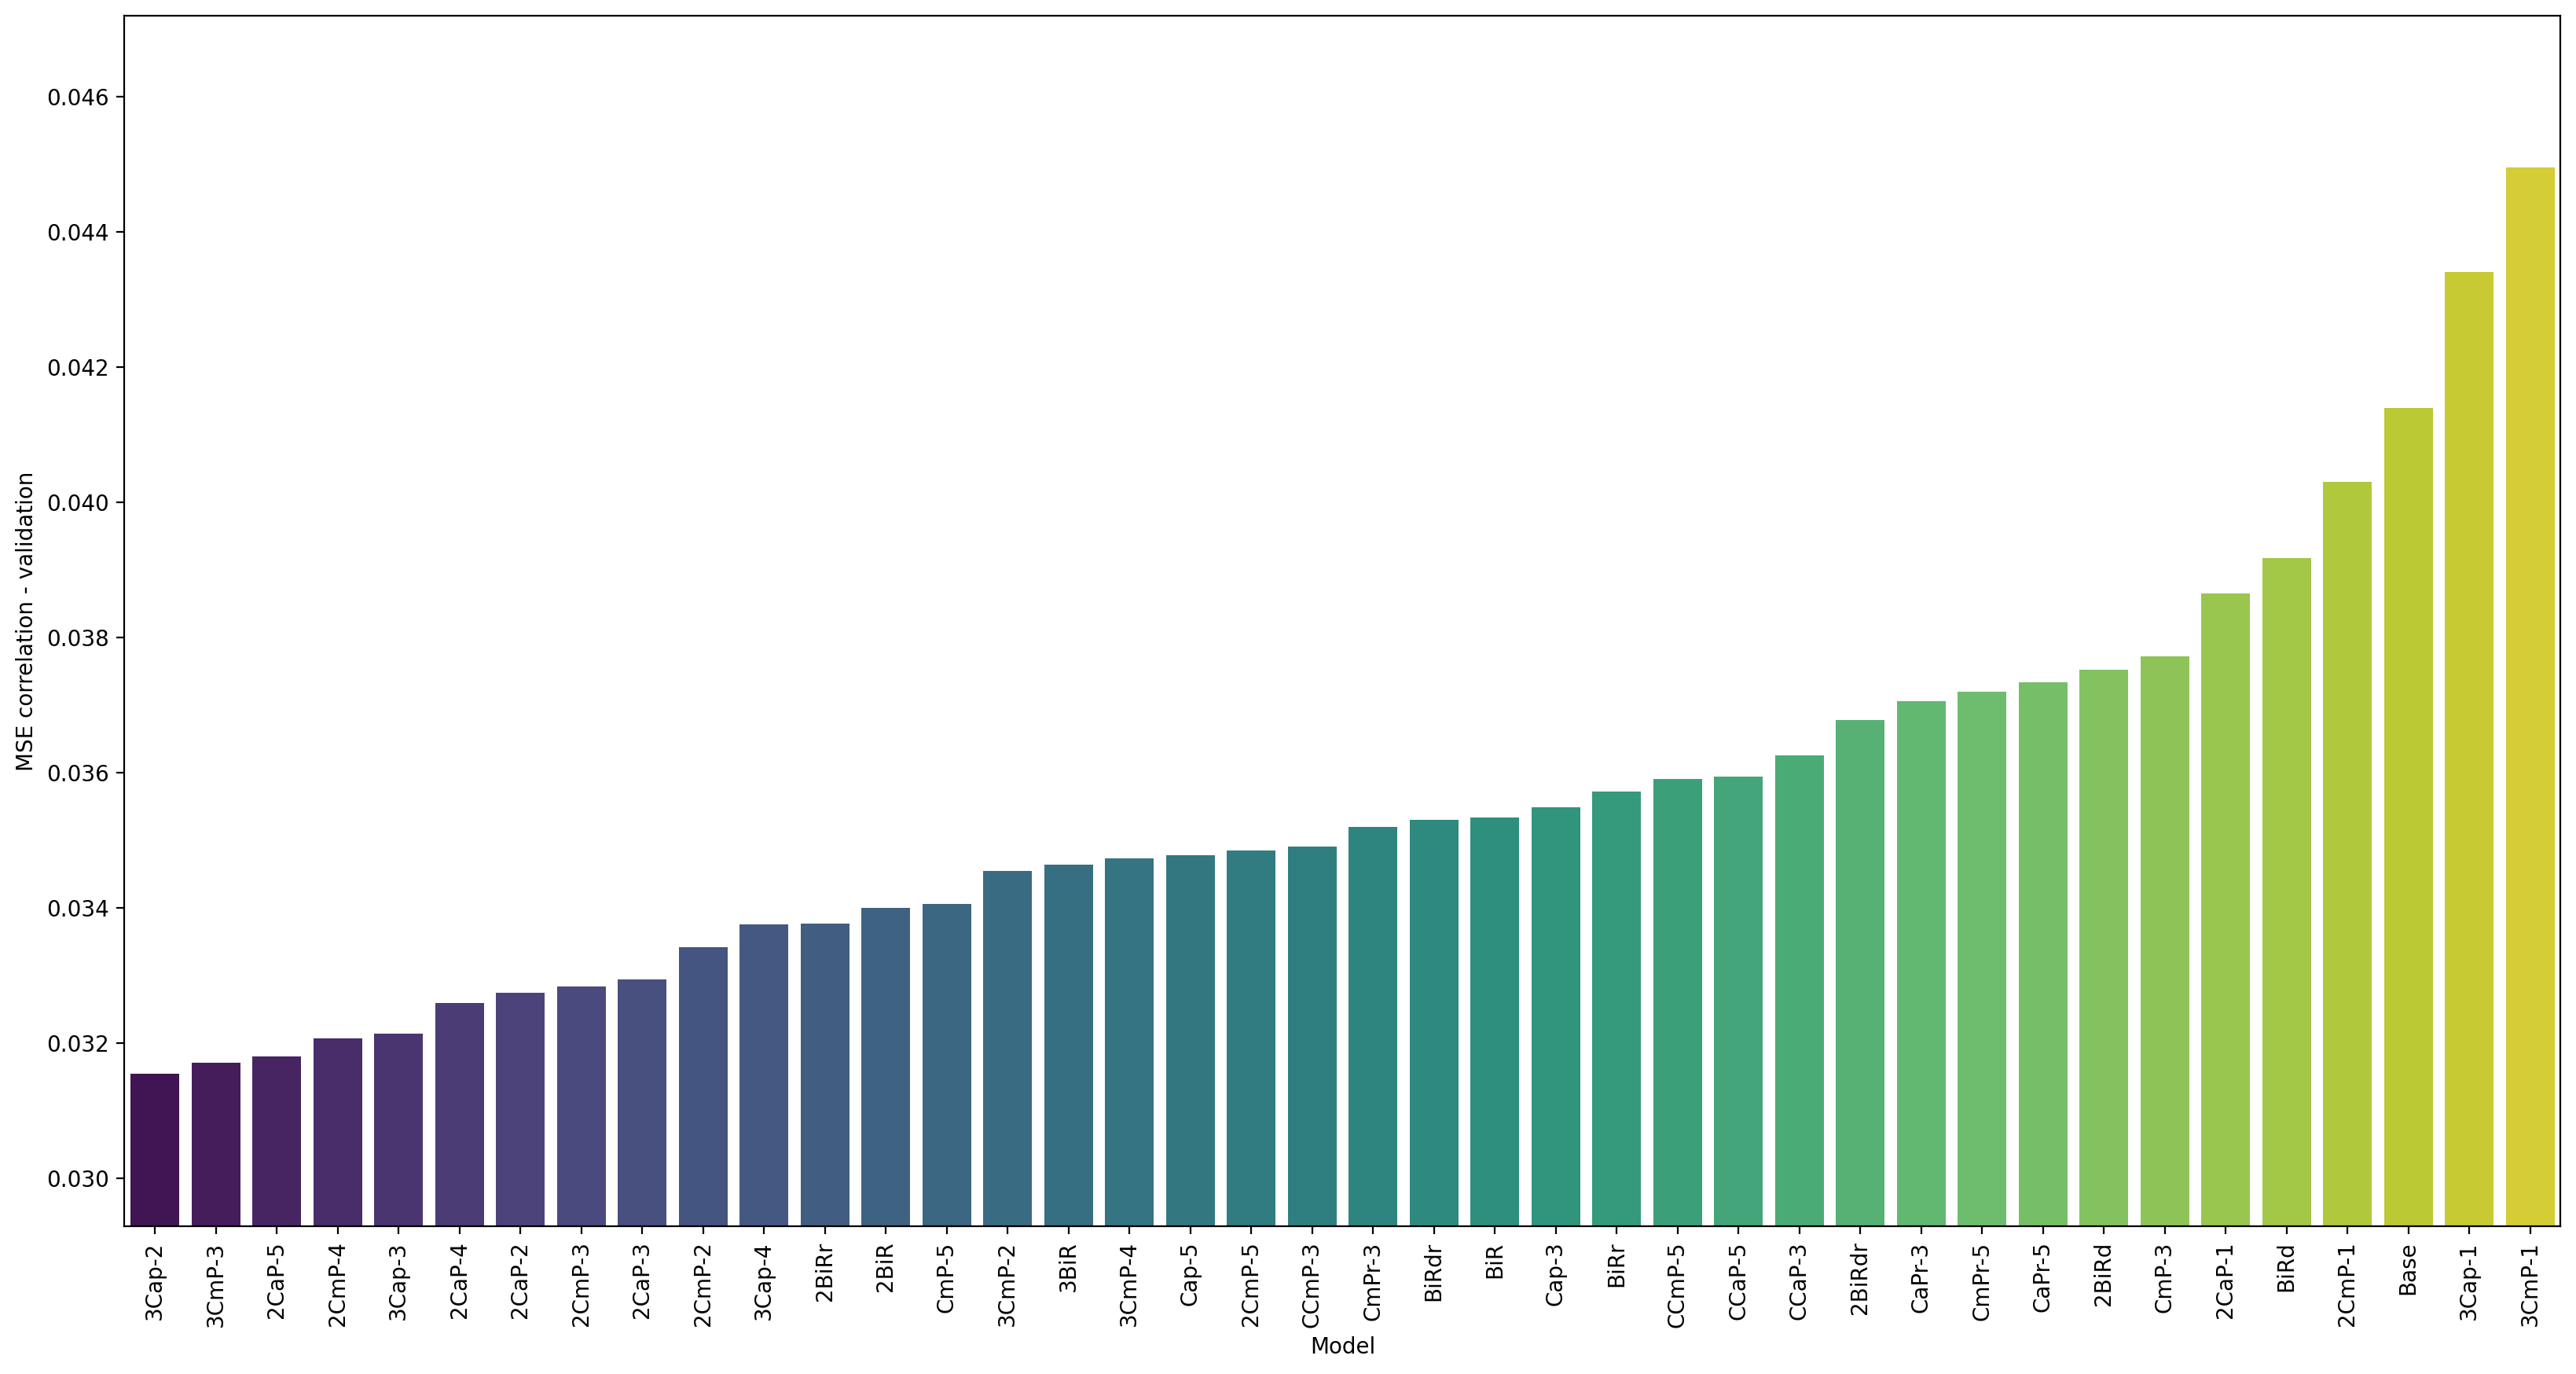

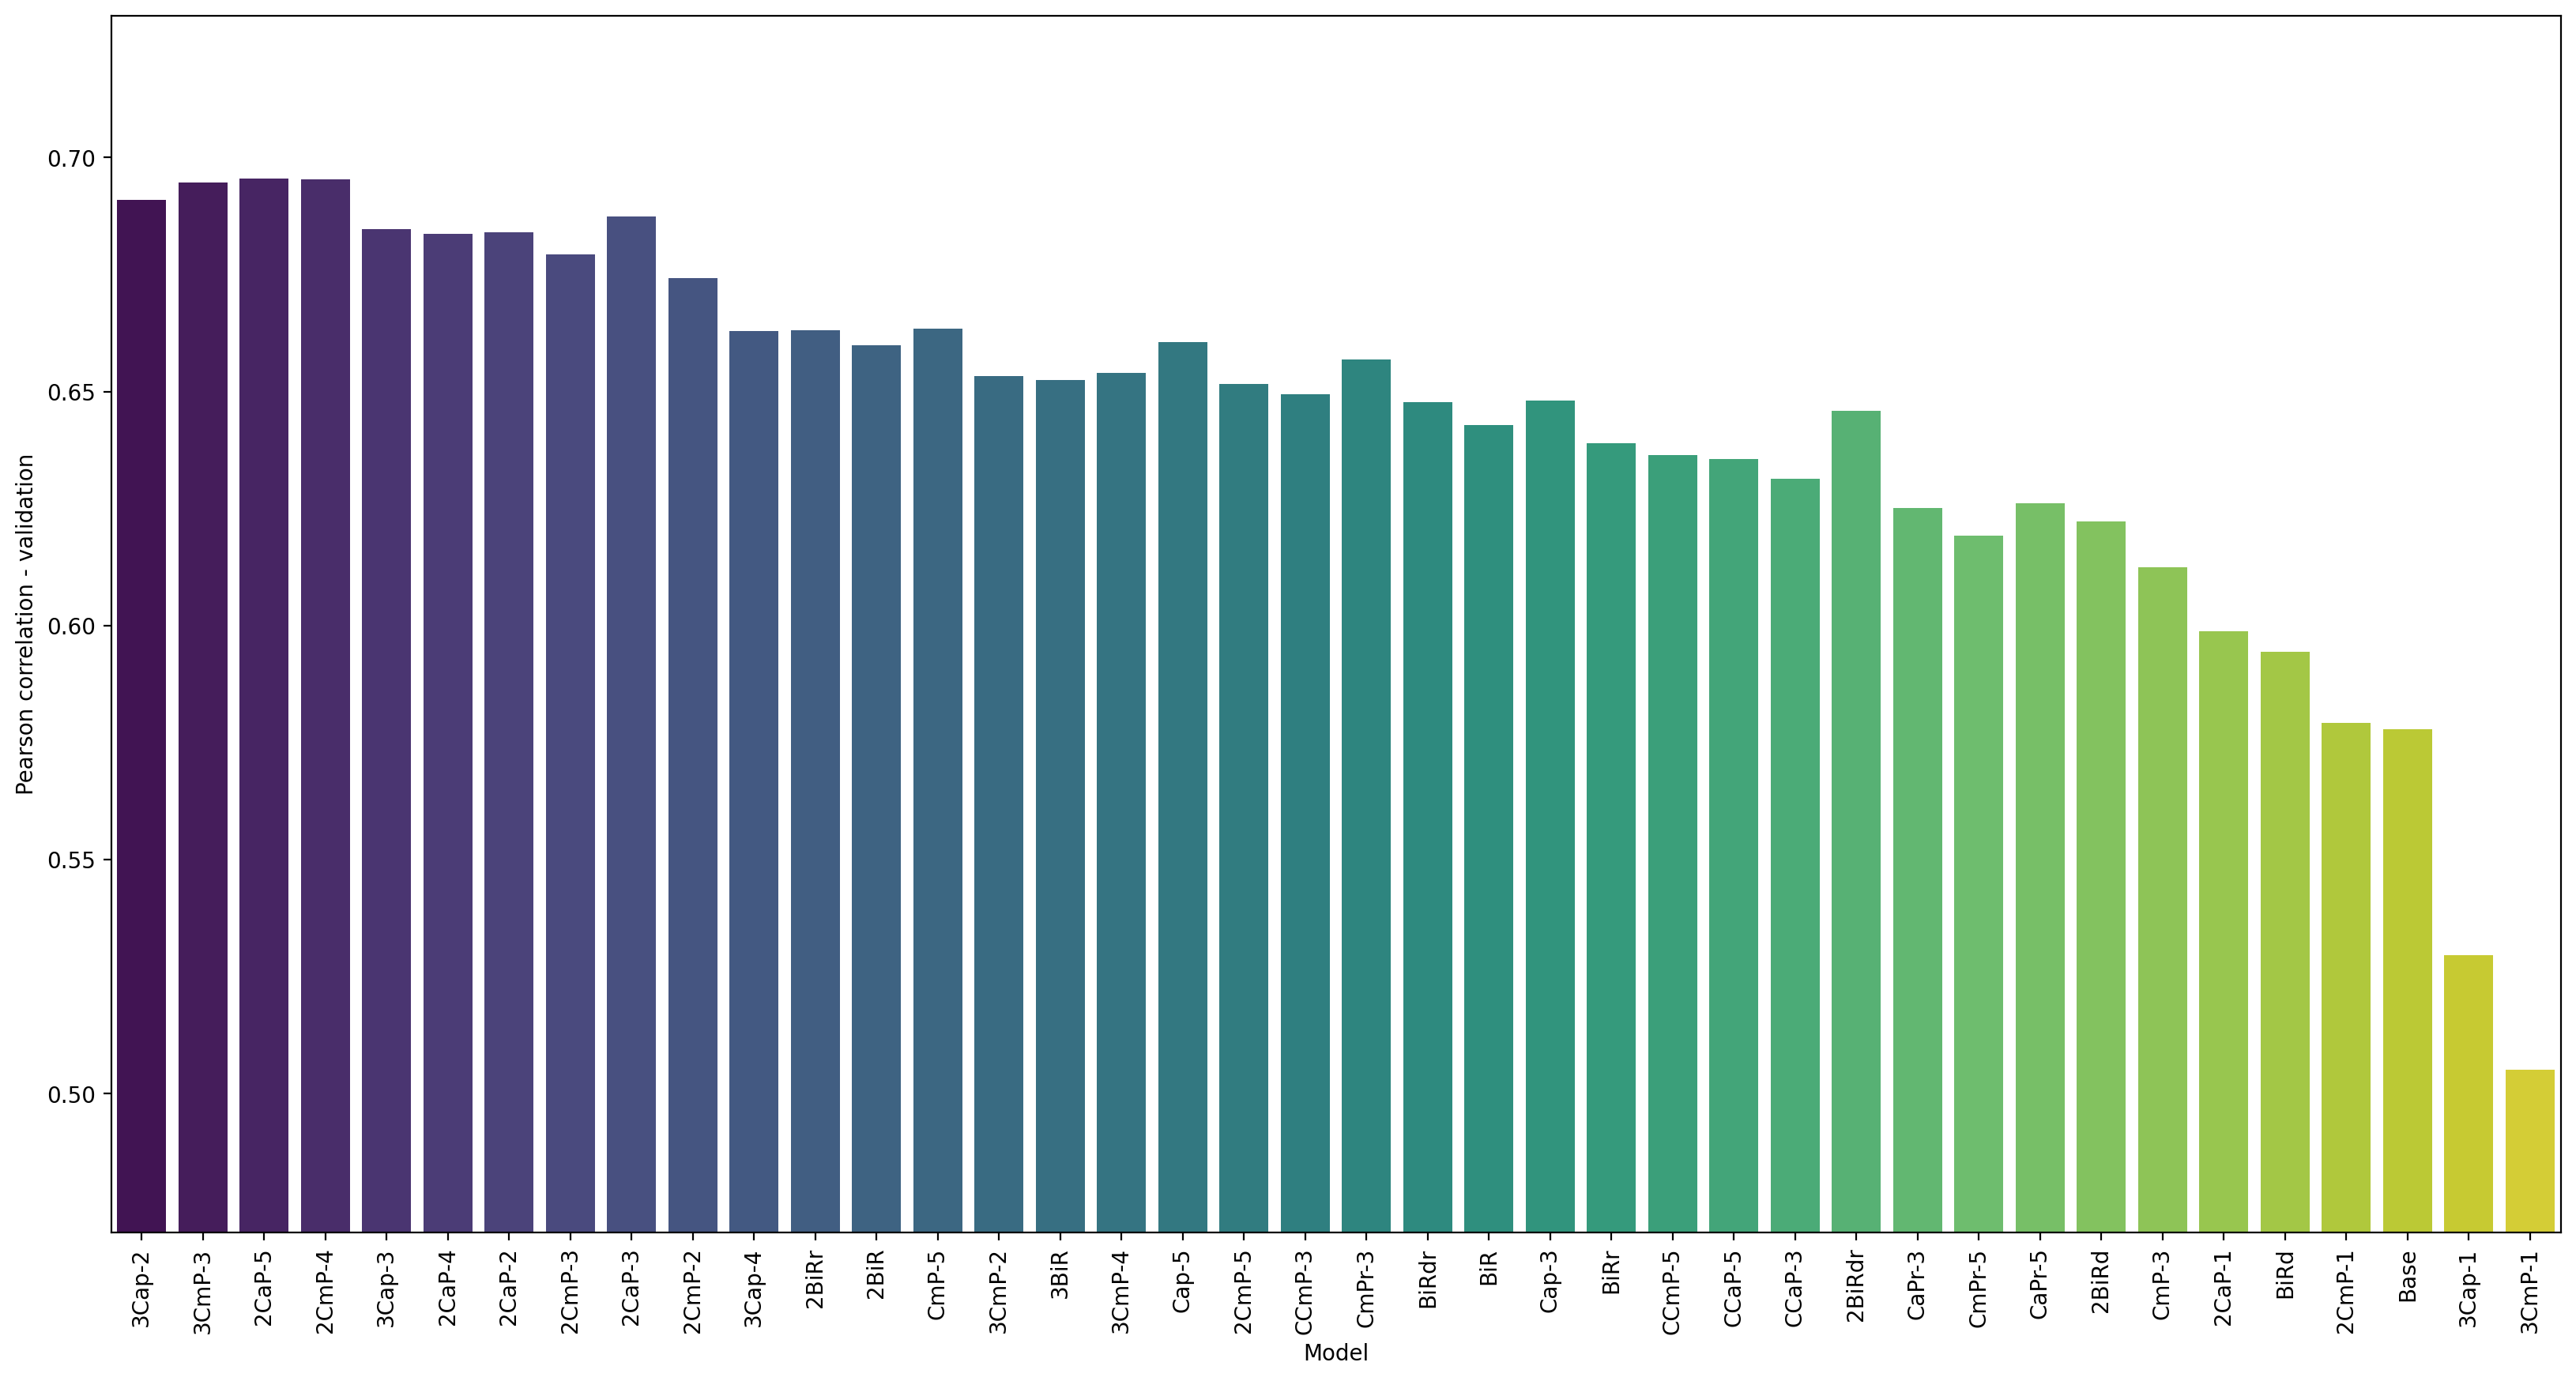

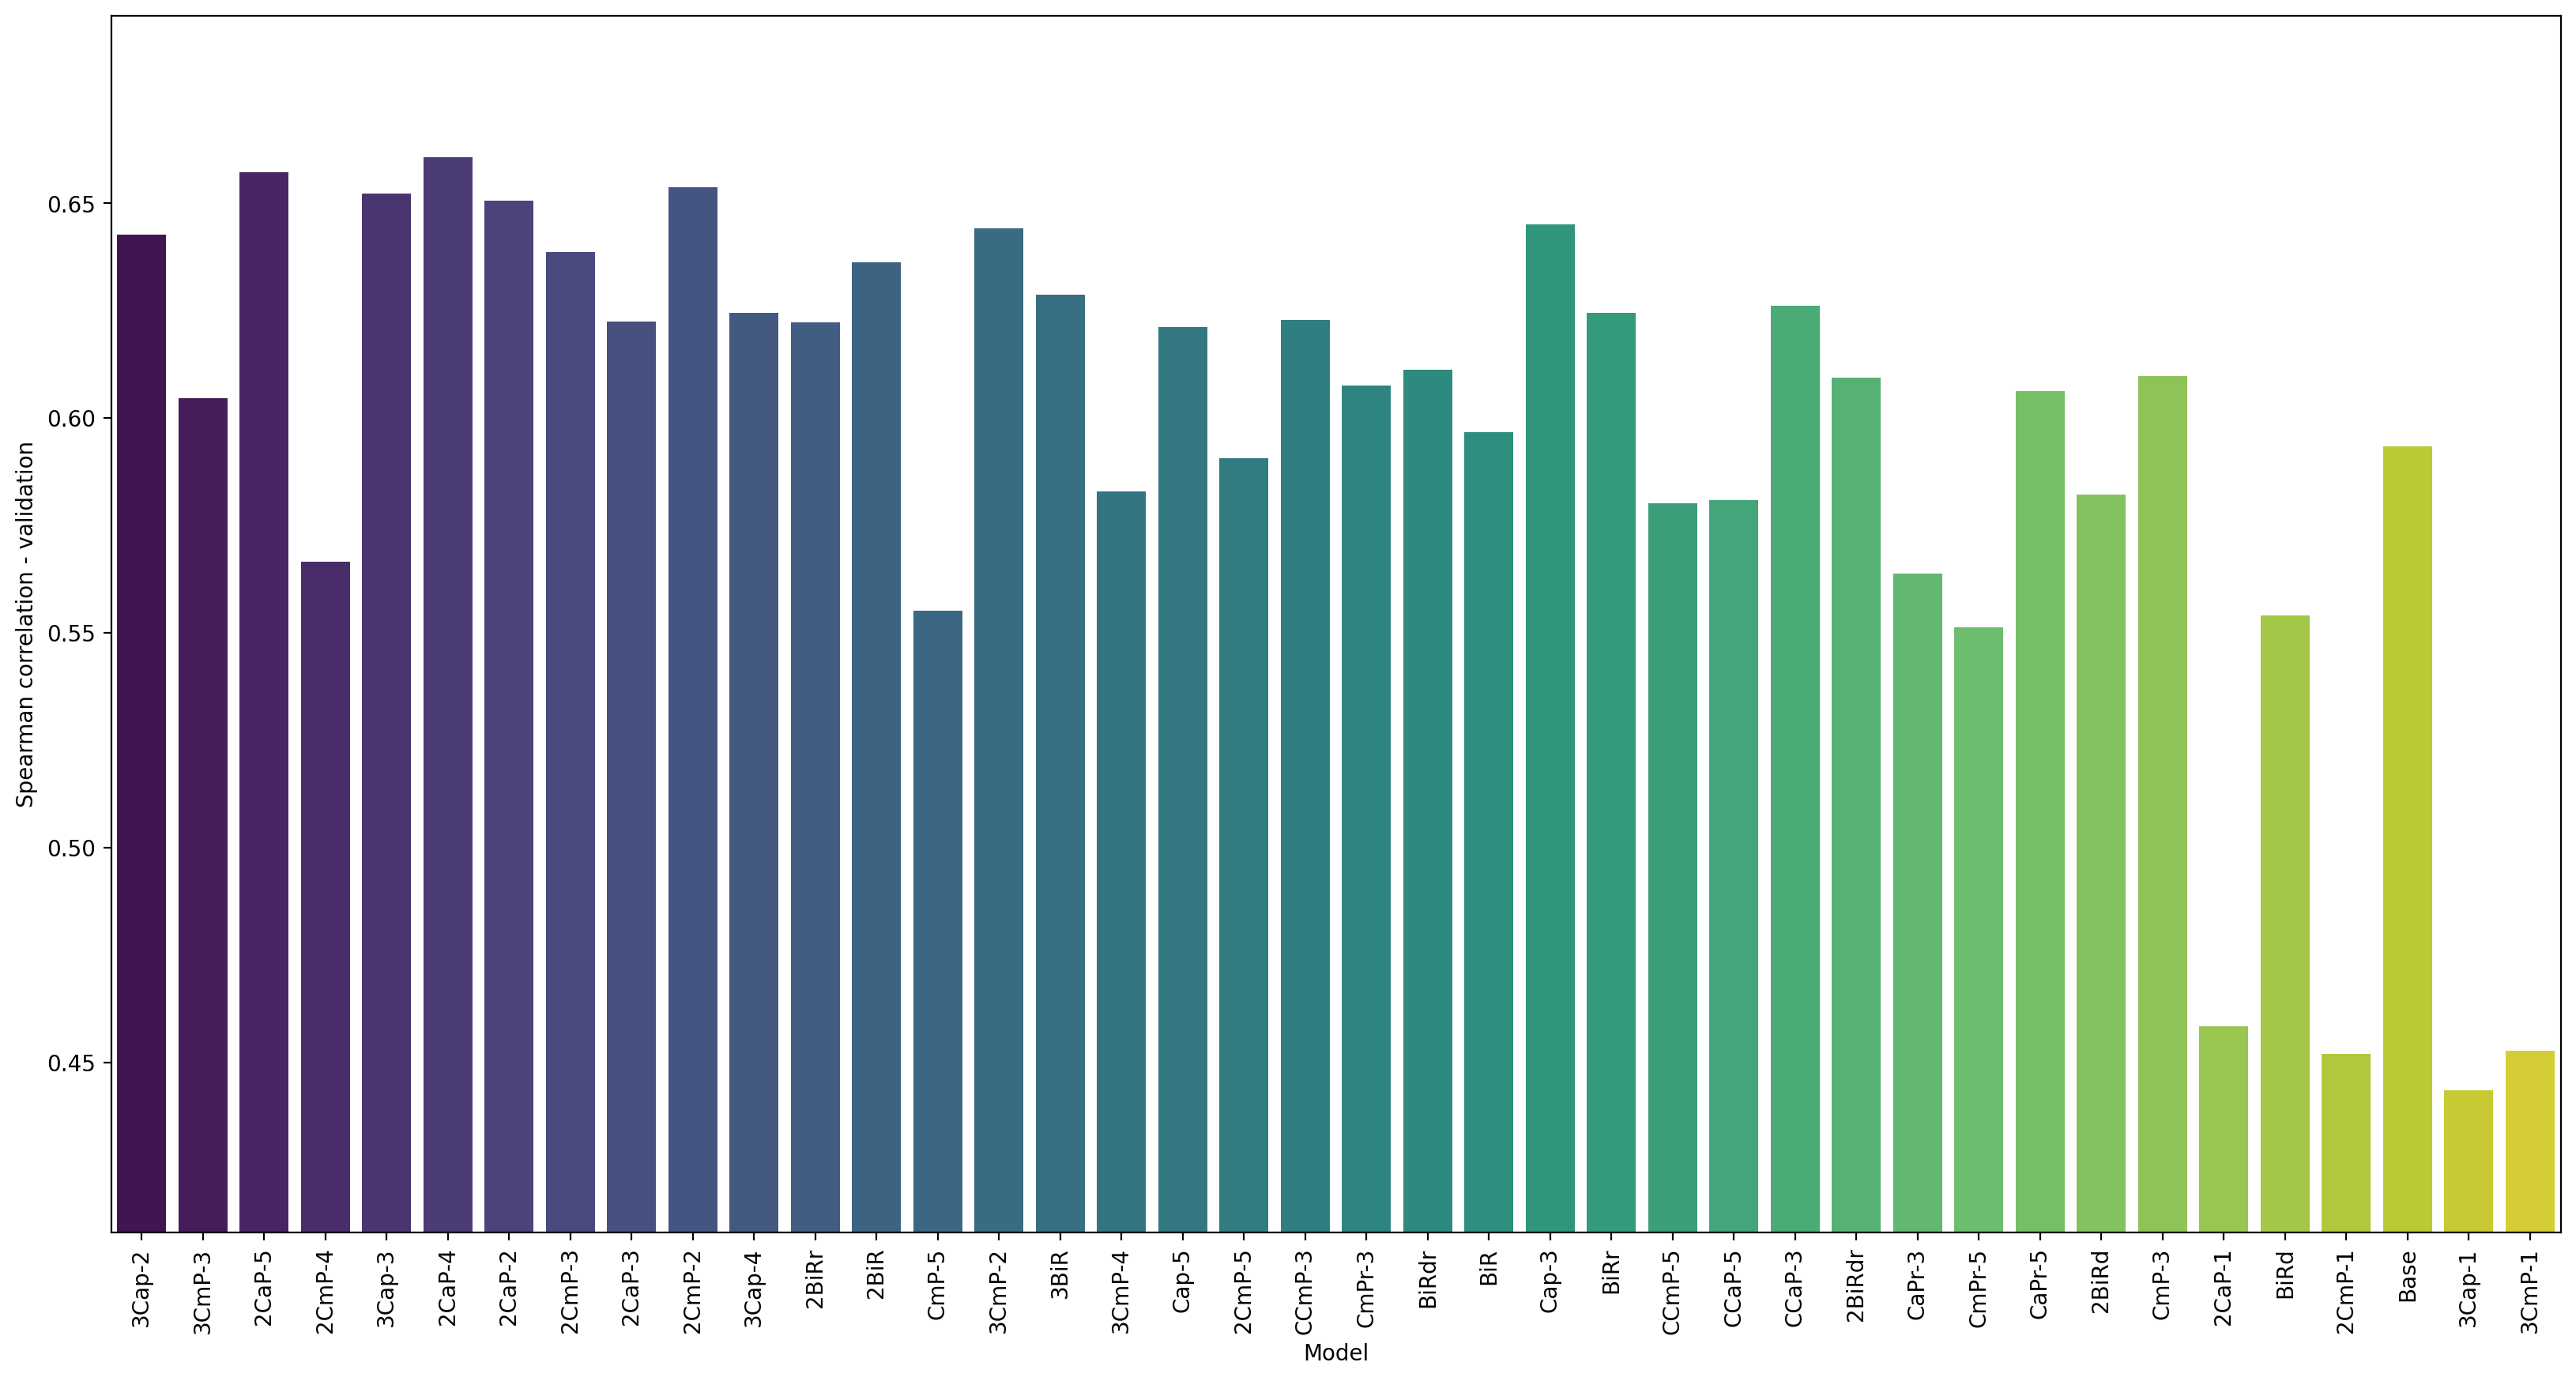

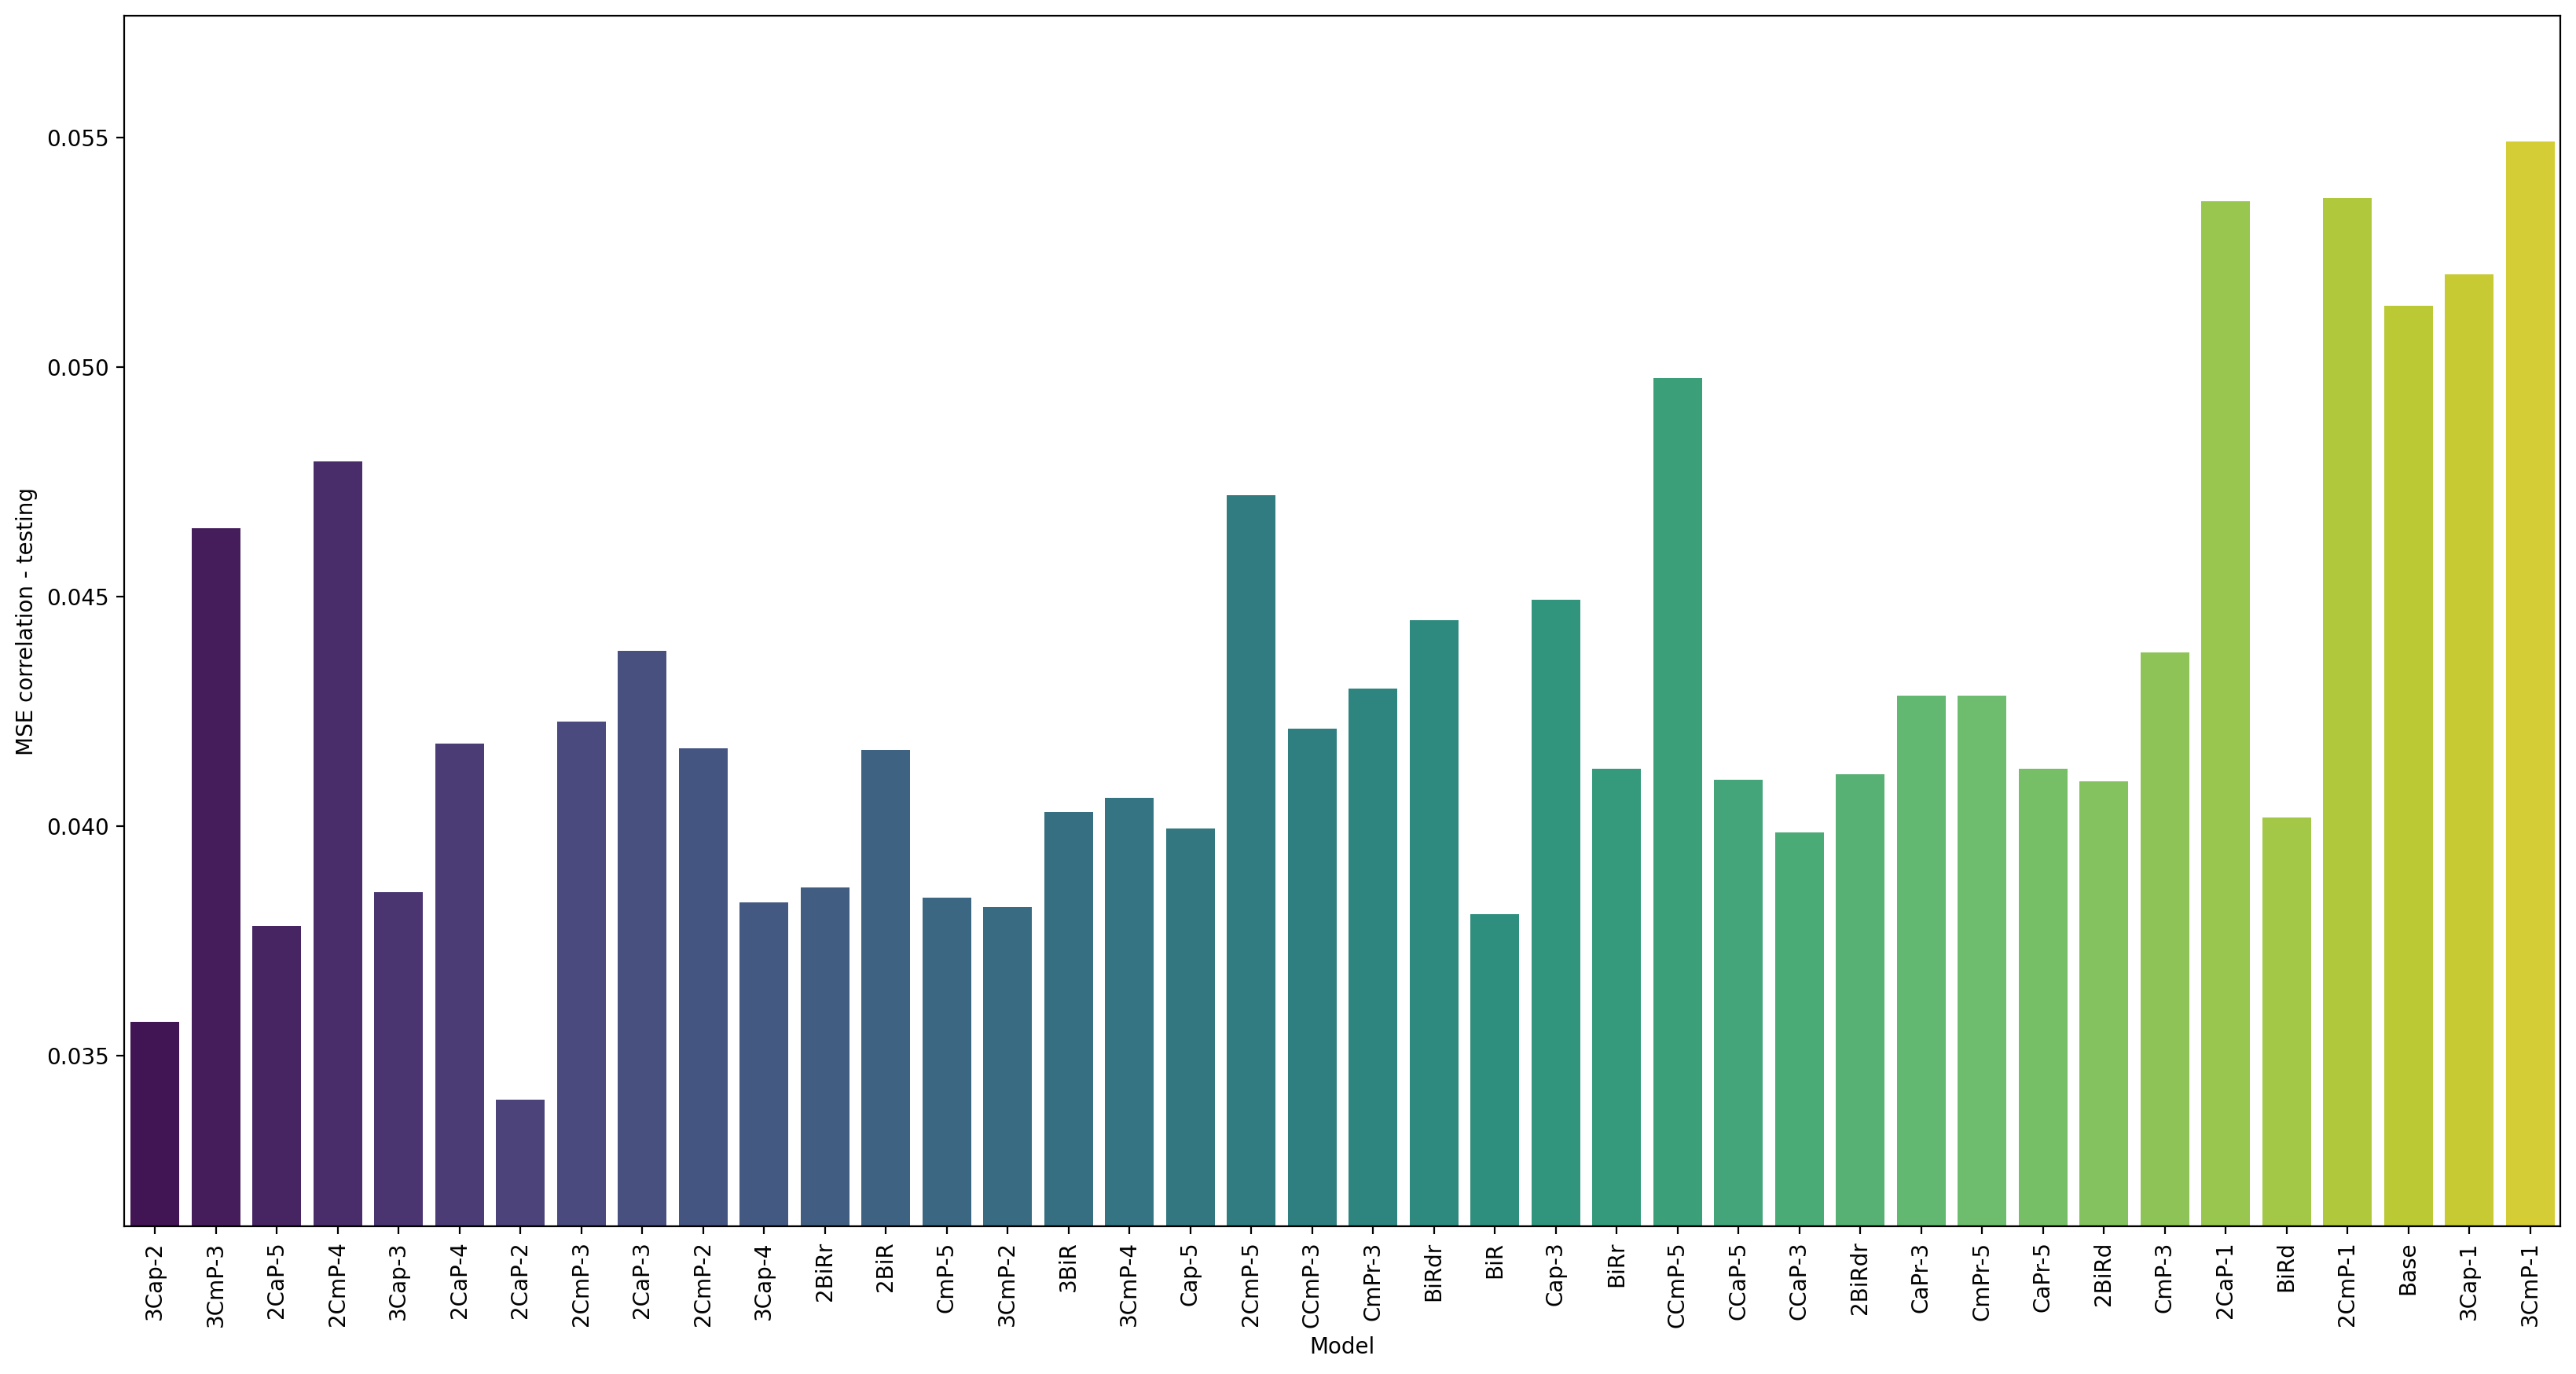

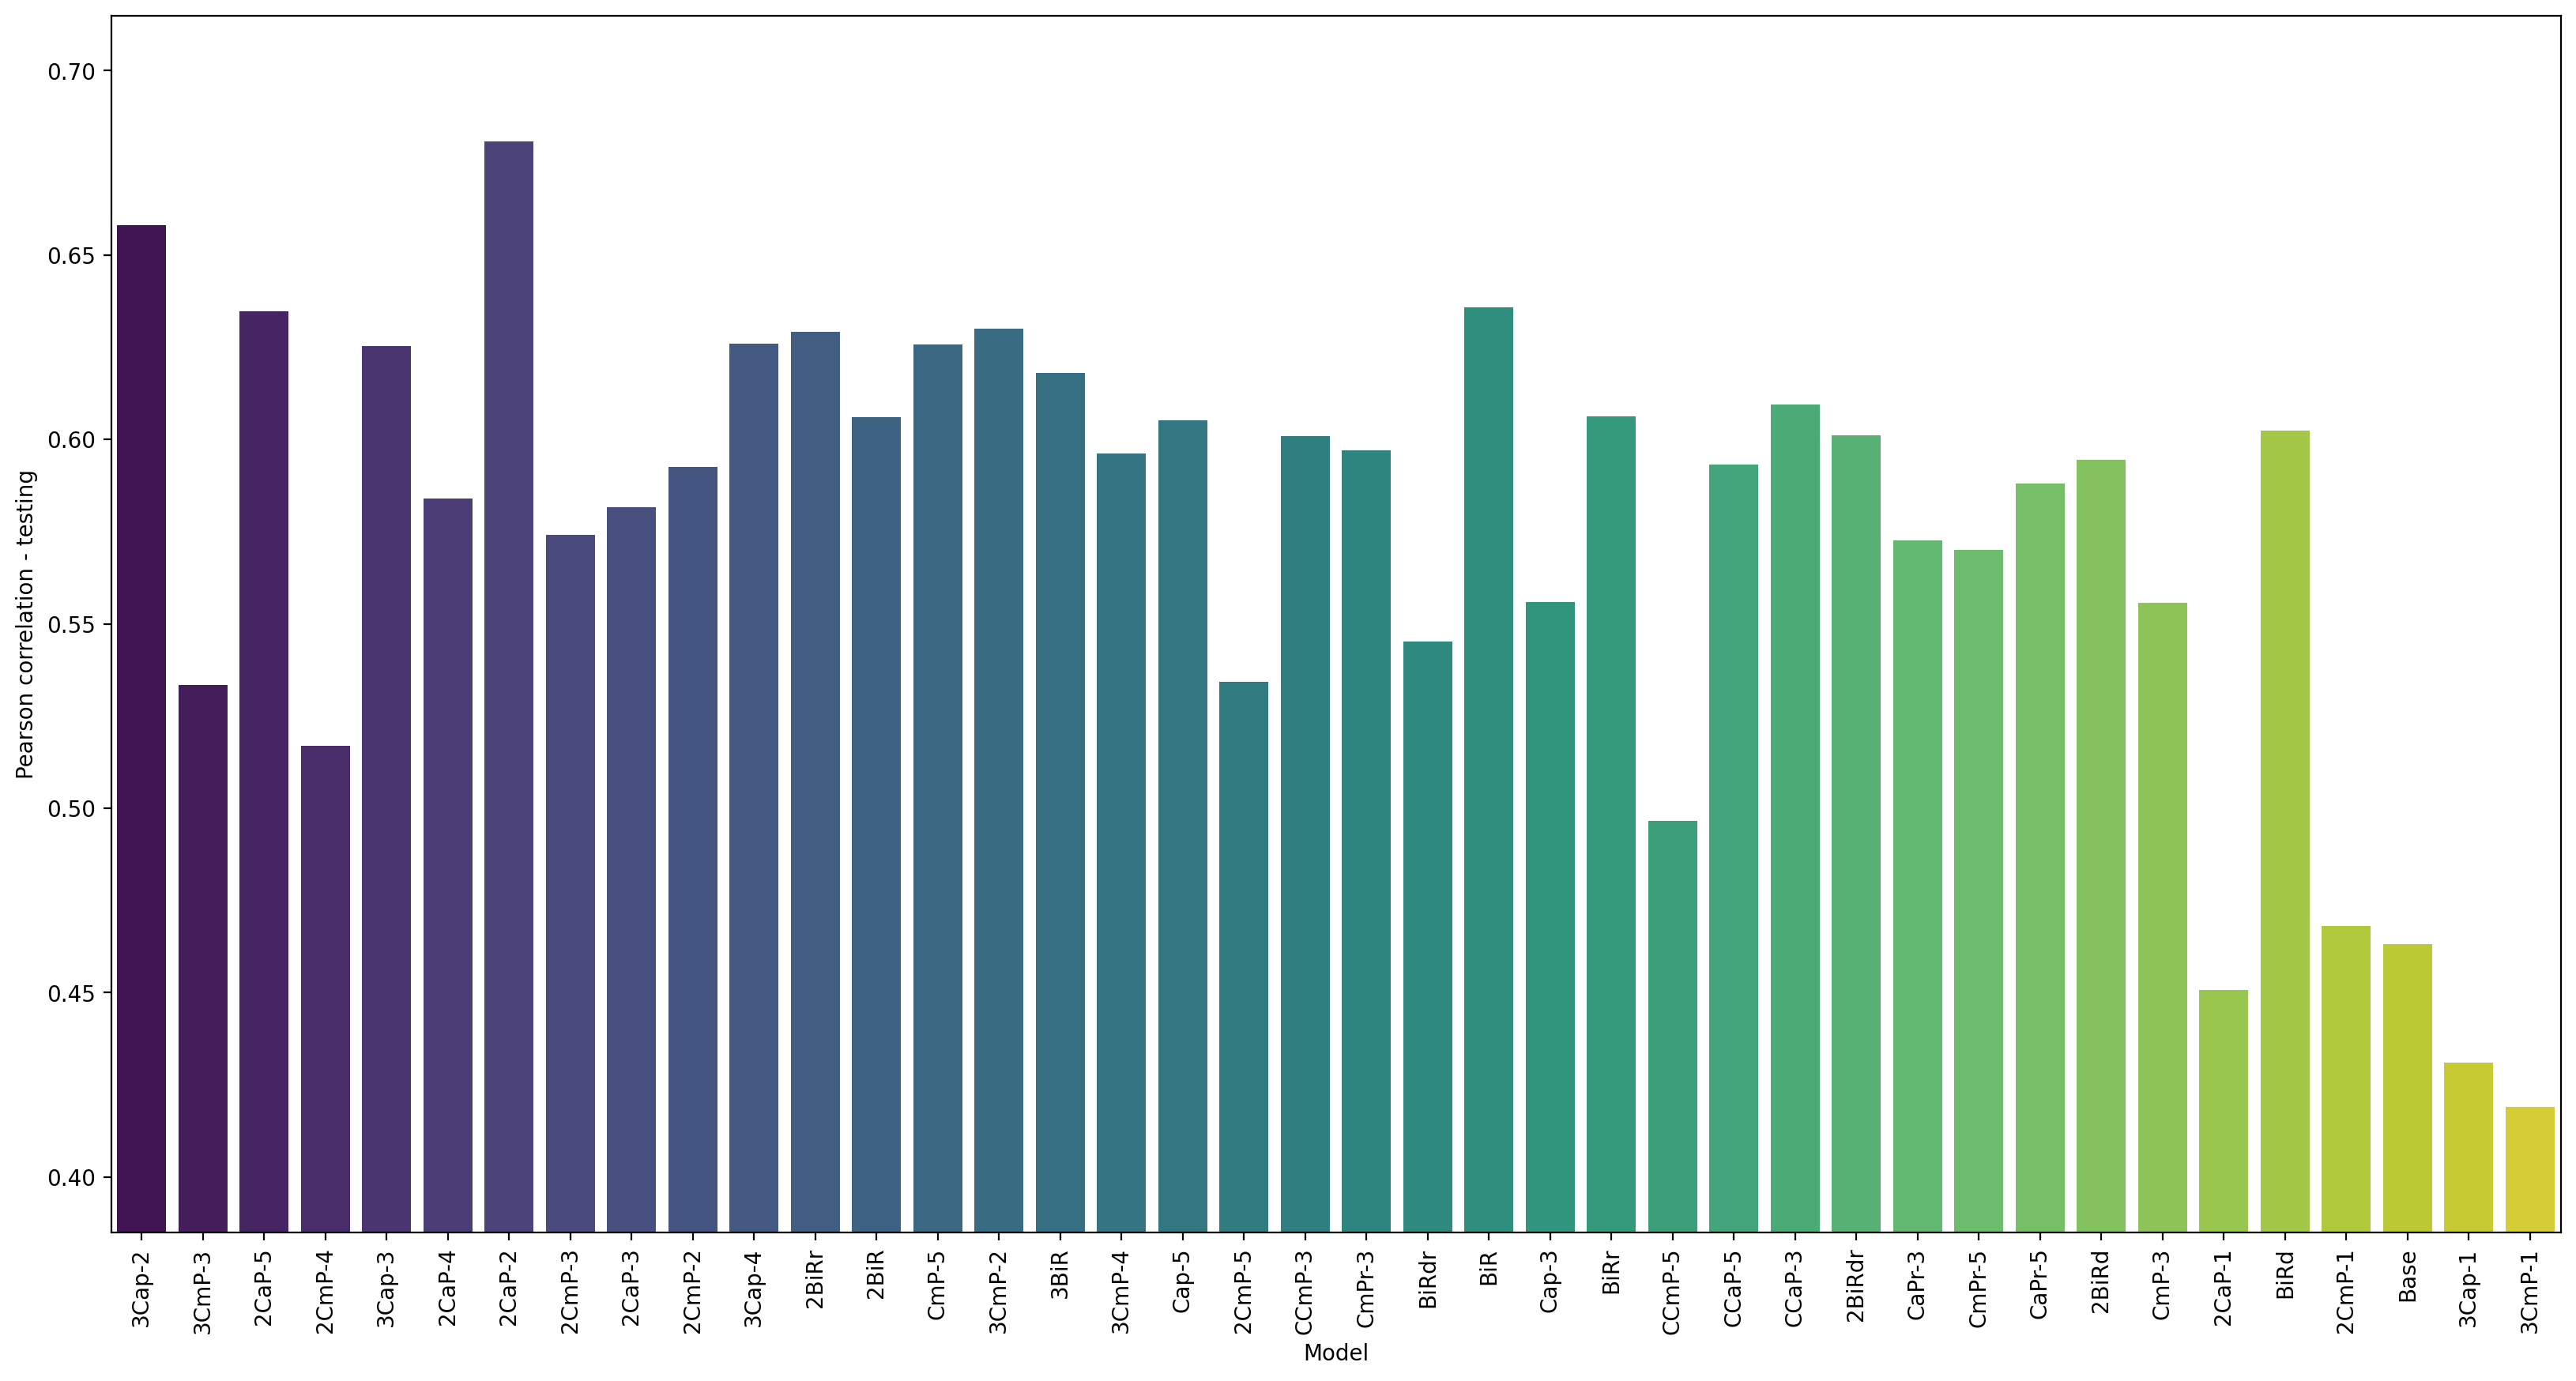

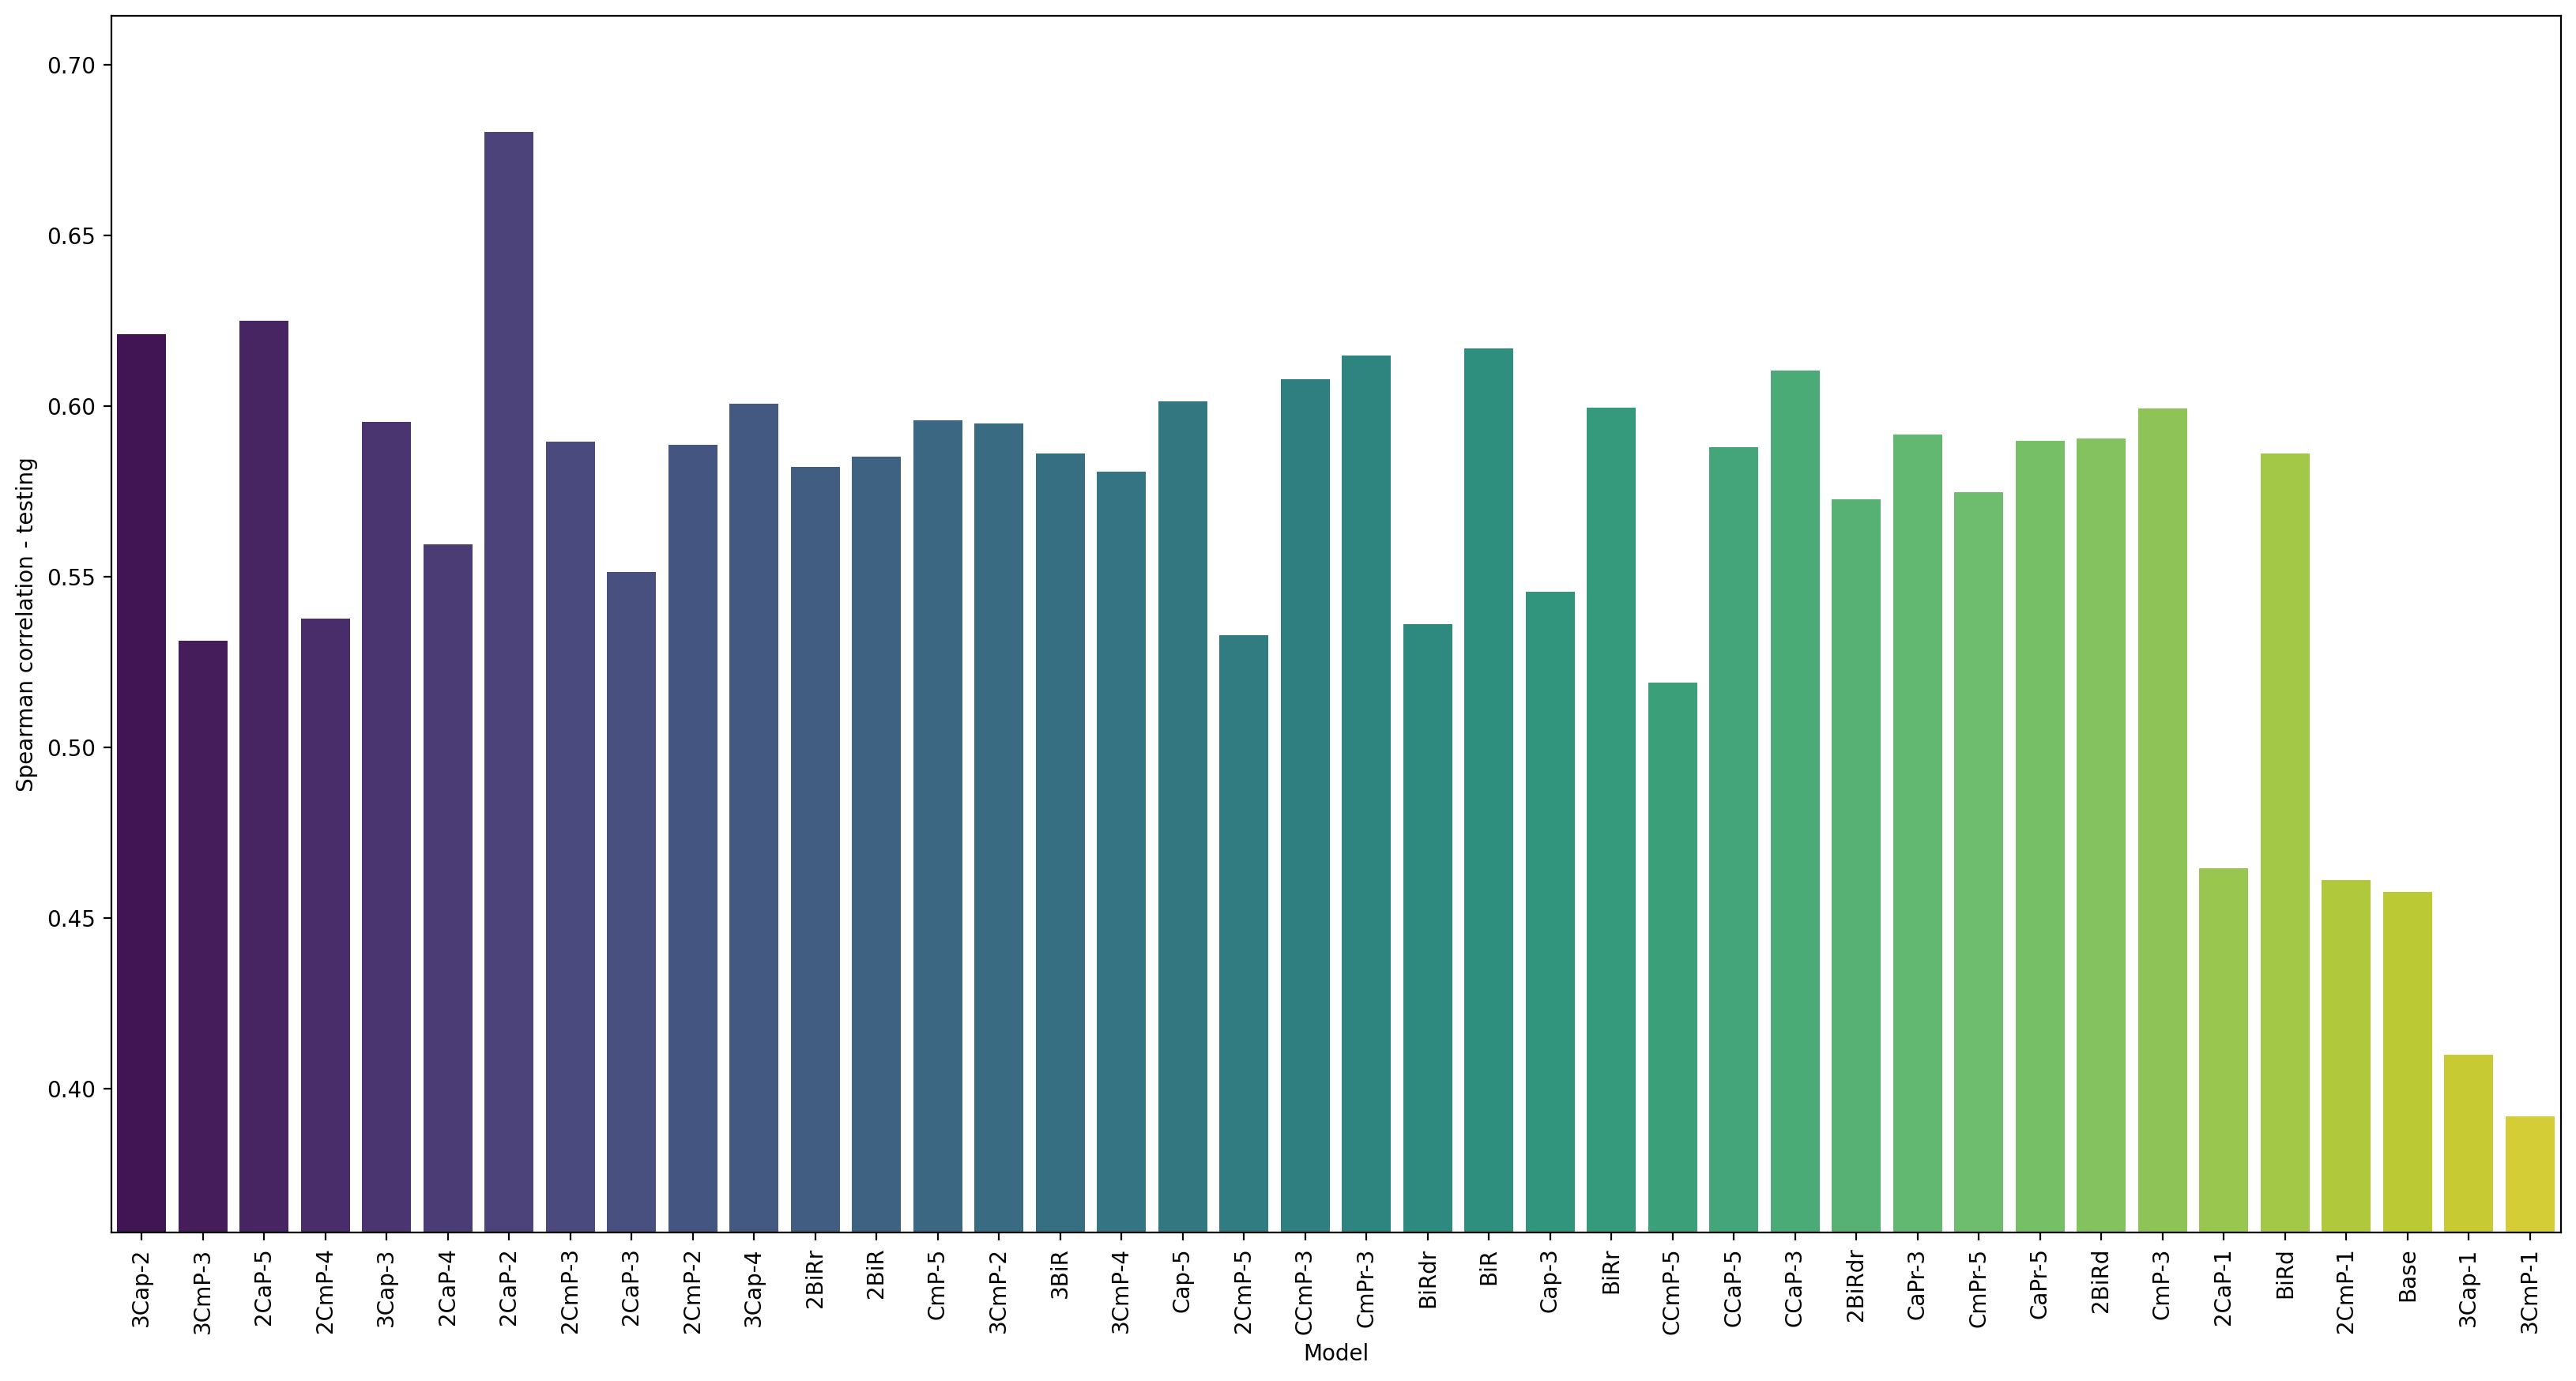

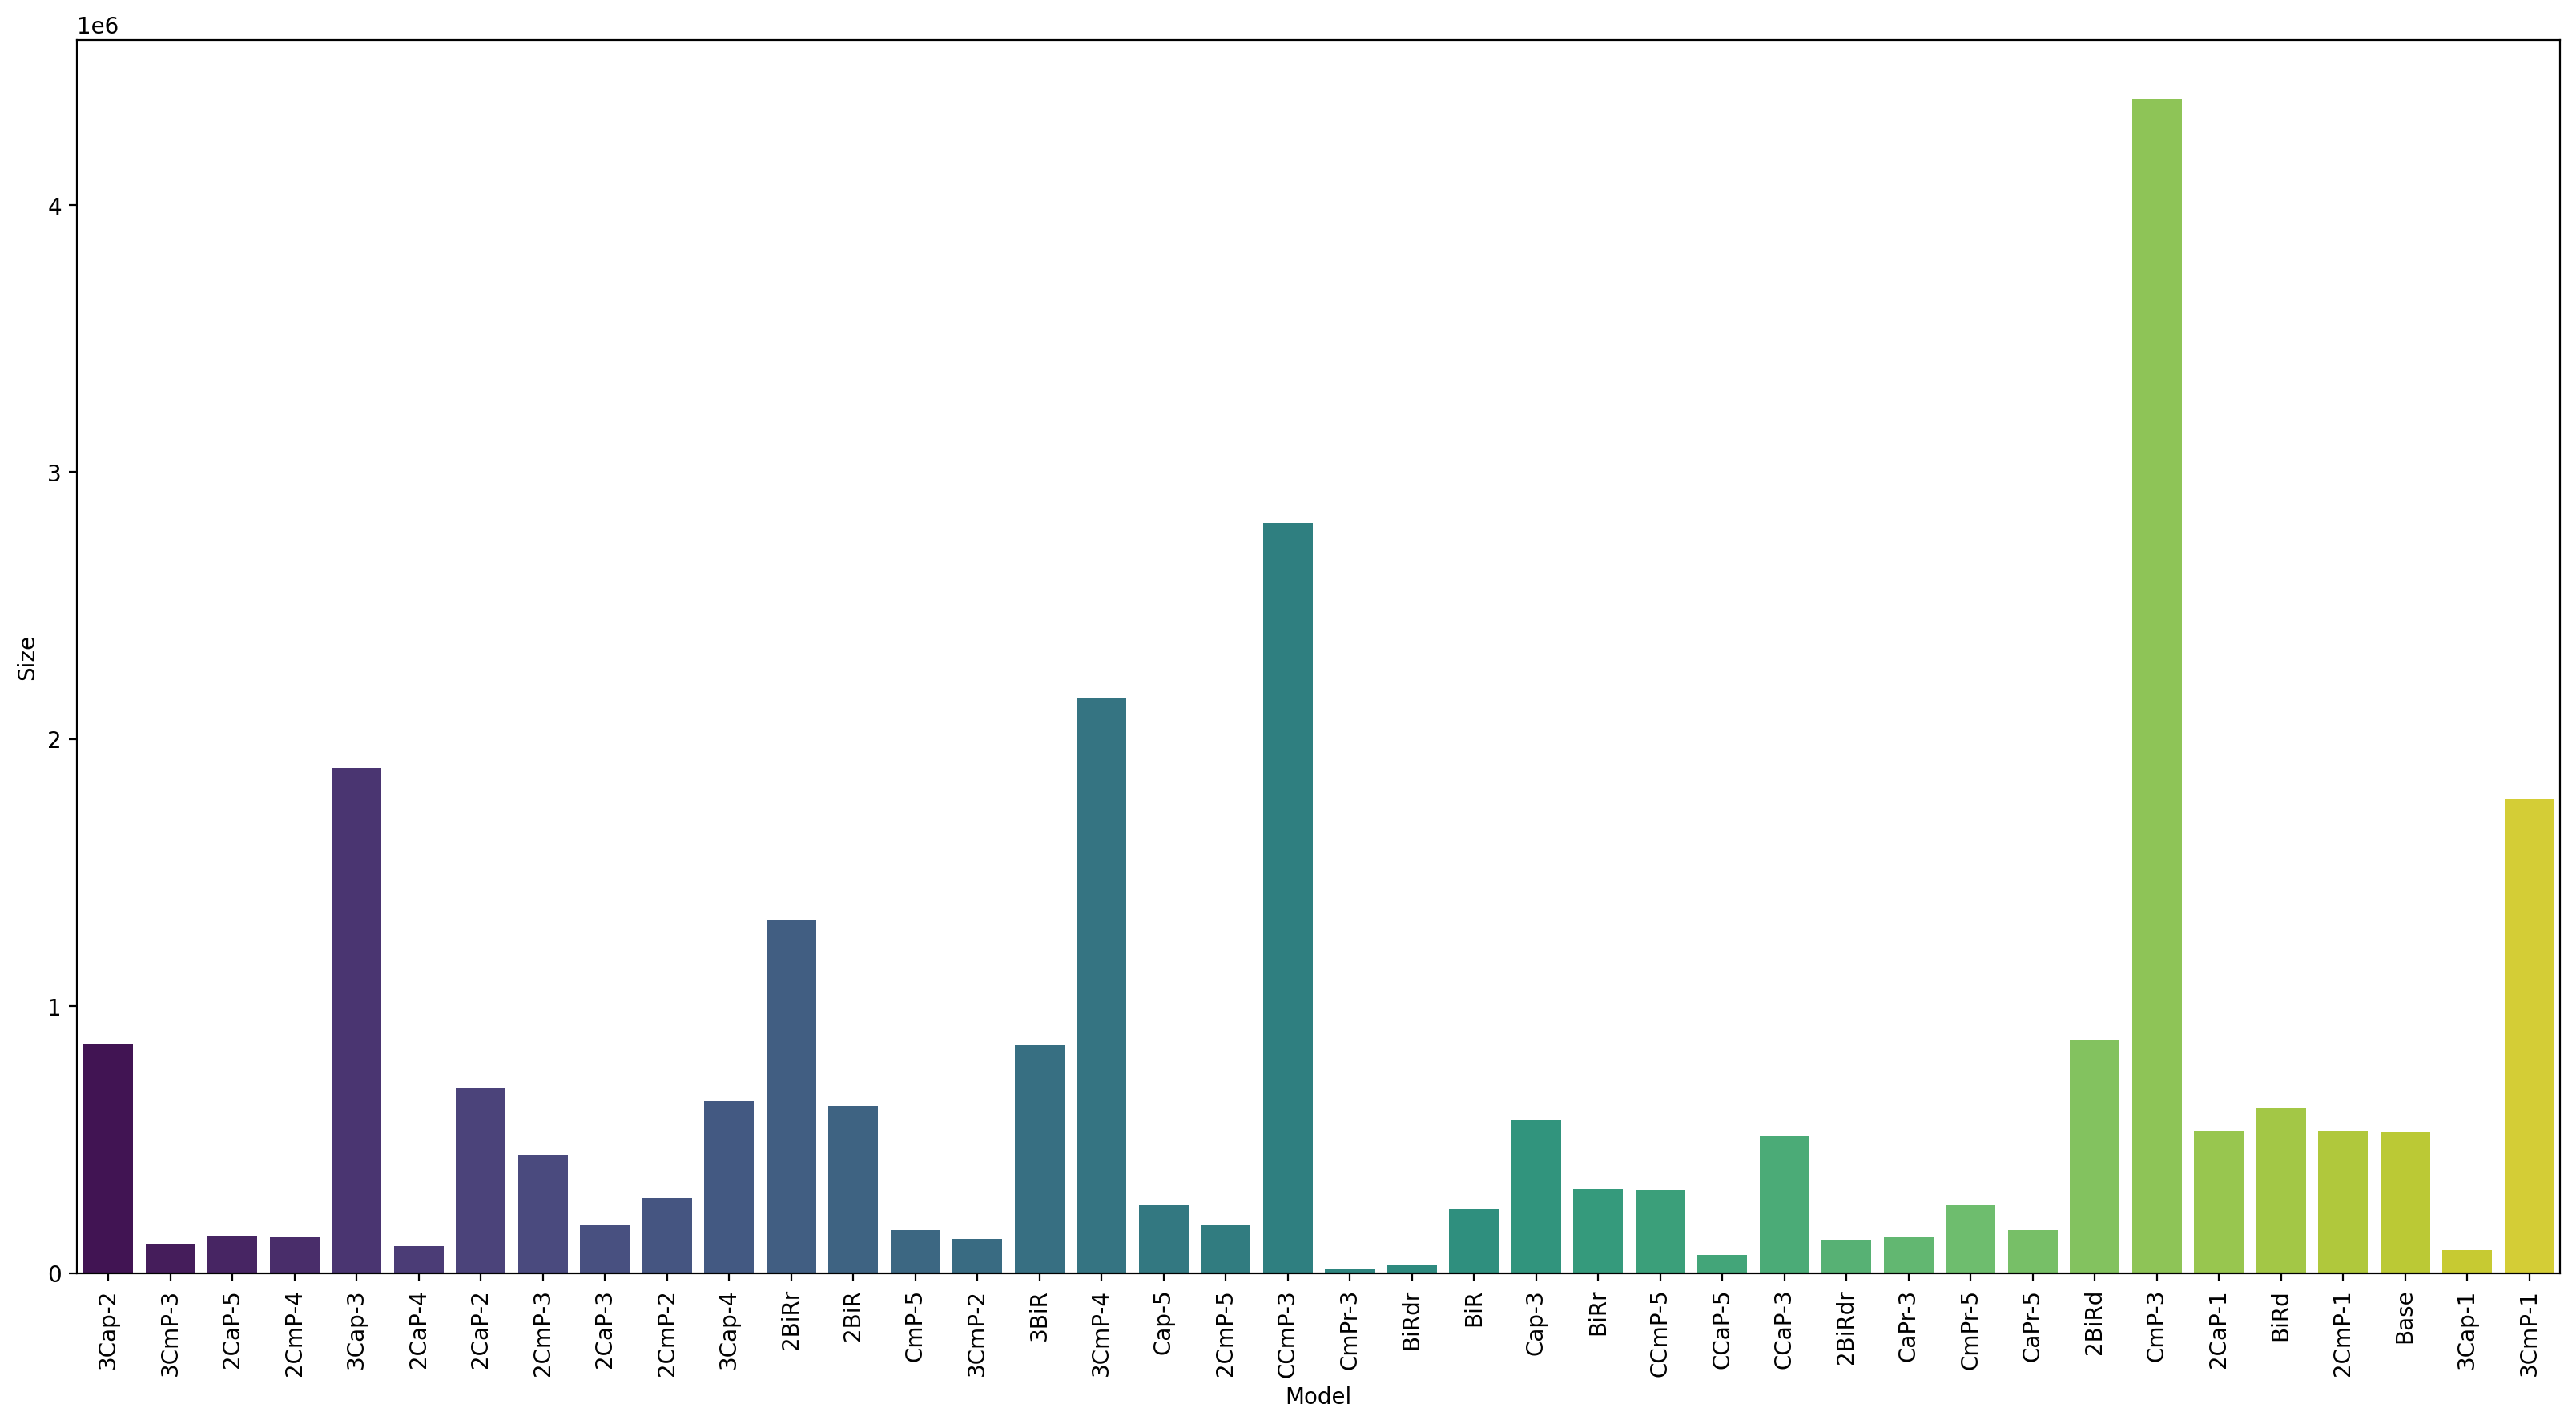

In [5]:
# TOTAL OVERVIEW #

sorted_names = image_multiple_models(base_folder, models, alternative_naming, palette, output_name='outputs/on-target_VAL_TEST.xlsx')

### Validation plate

There is an extra plate that can be used for extra testing.

#### read in data

In [6]:
plate_h = "20250407_Validation_plate_h.xlsx"

test_plate = pd.read_excel(plate_h)
test_plate = test_plate.loc[:,["Input Seq-Cpf1 (34bp)", "Mean modified (%)"]]
test_plate.columns = ["crRNA", "efficiency"]

X_h = preprocess_RNA(test_plate["crRNA"].to_numpy())
y_h = test_plate["efficiency"].to_numpy()/100.0

2026-01-29 09:42:04.152295: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-01-29 09:42:04.176581: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-01-29 09:42:04.176618: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-01-29 09:42:04.177875: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-01-29 09:42:04.177903: I external/local_xla/xla/stream_executor

#### Perform testing

2026-01-29 09:42:06.173061: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-01-29 09:42:06.246030: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


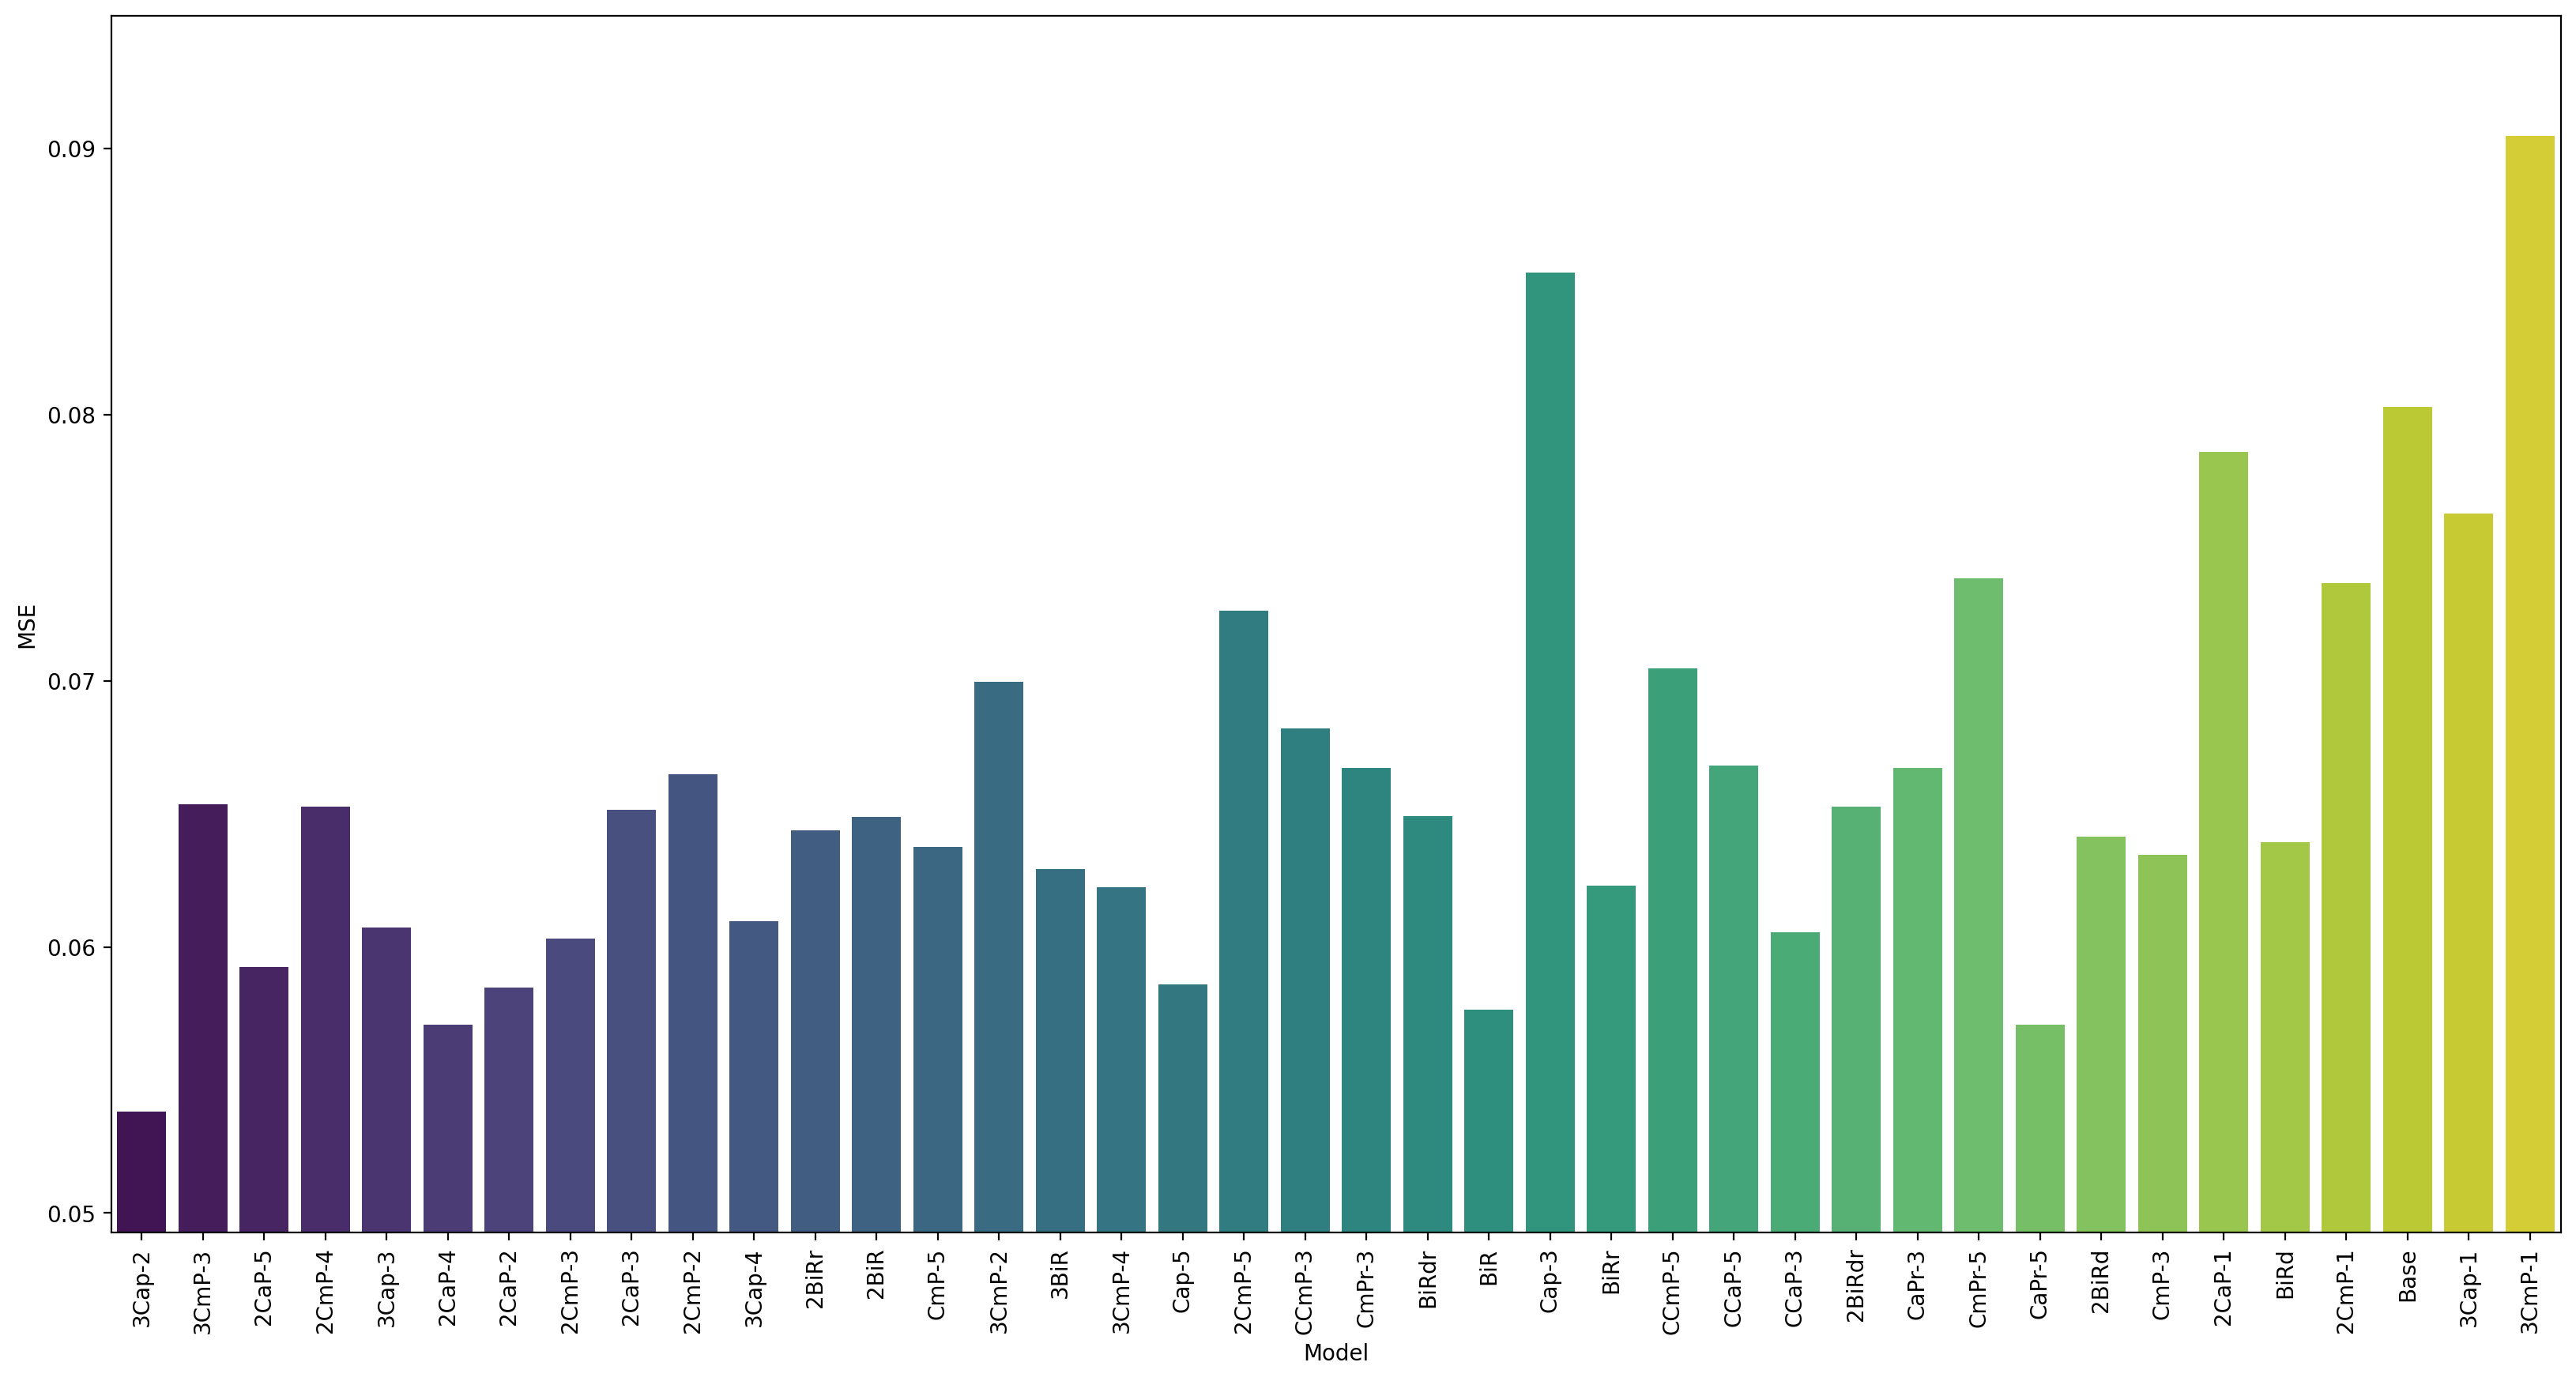

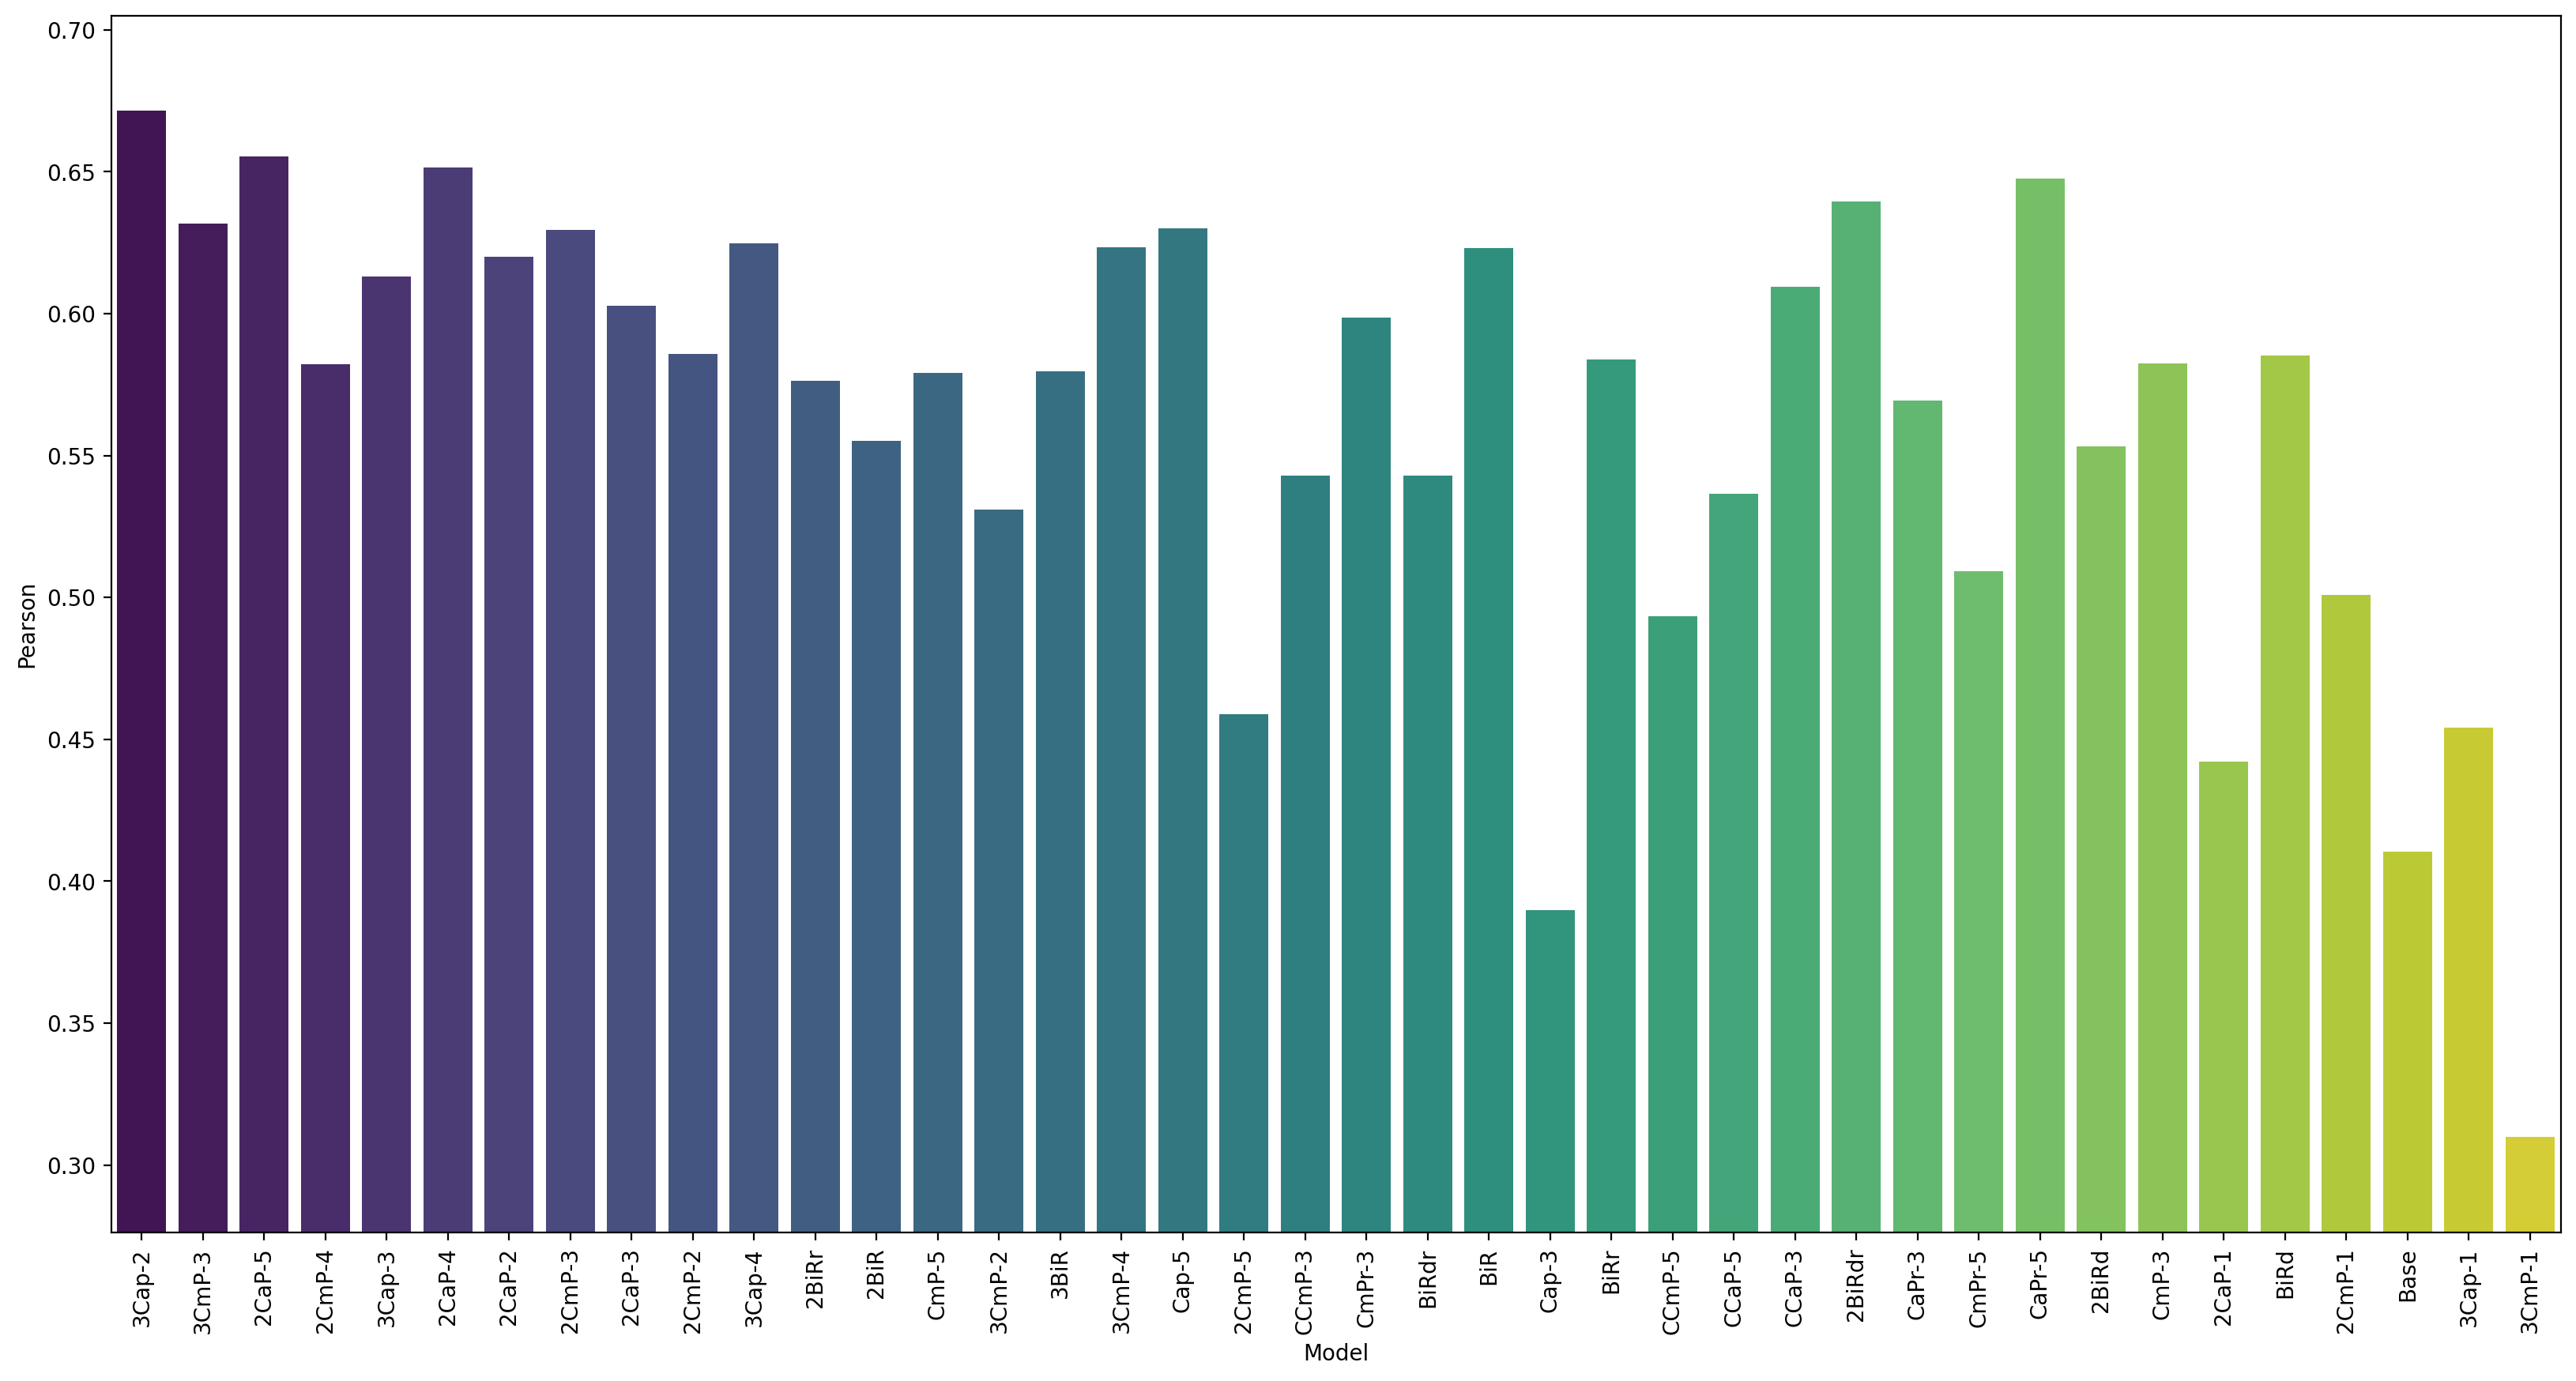

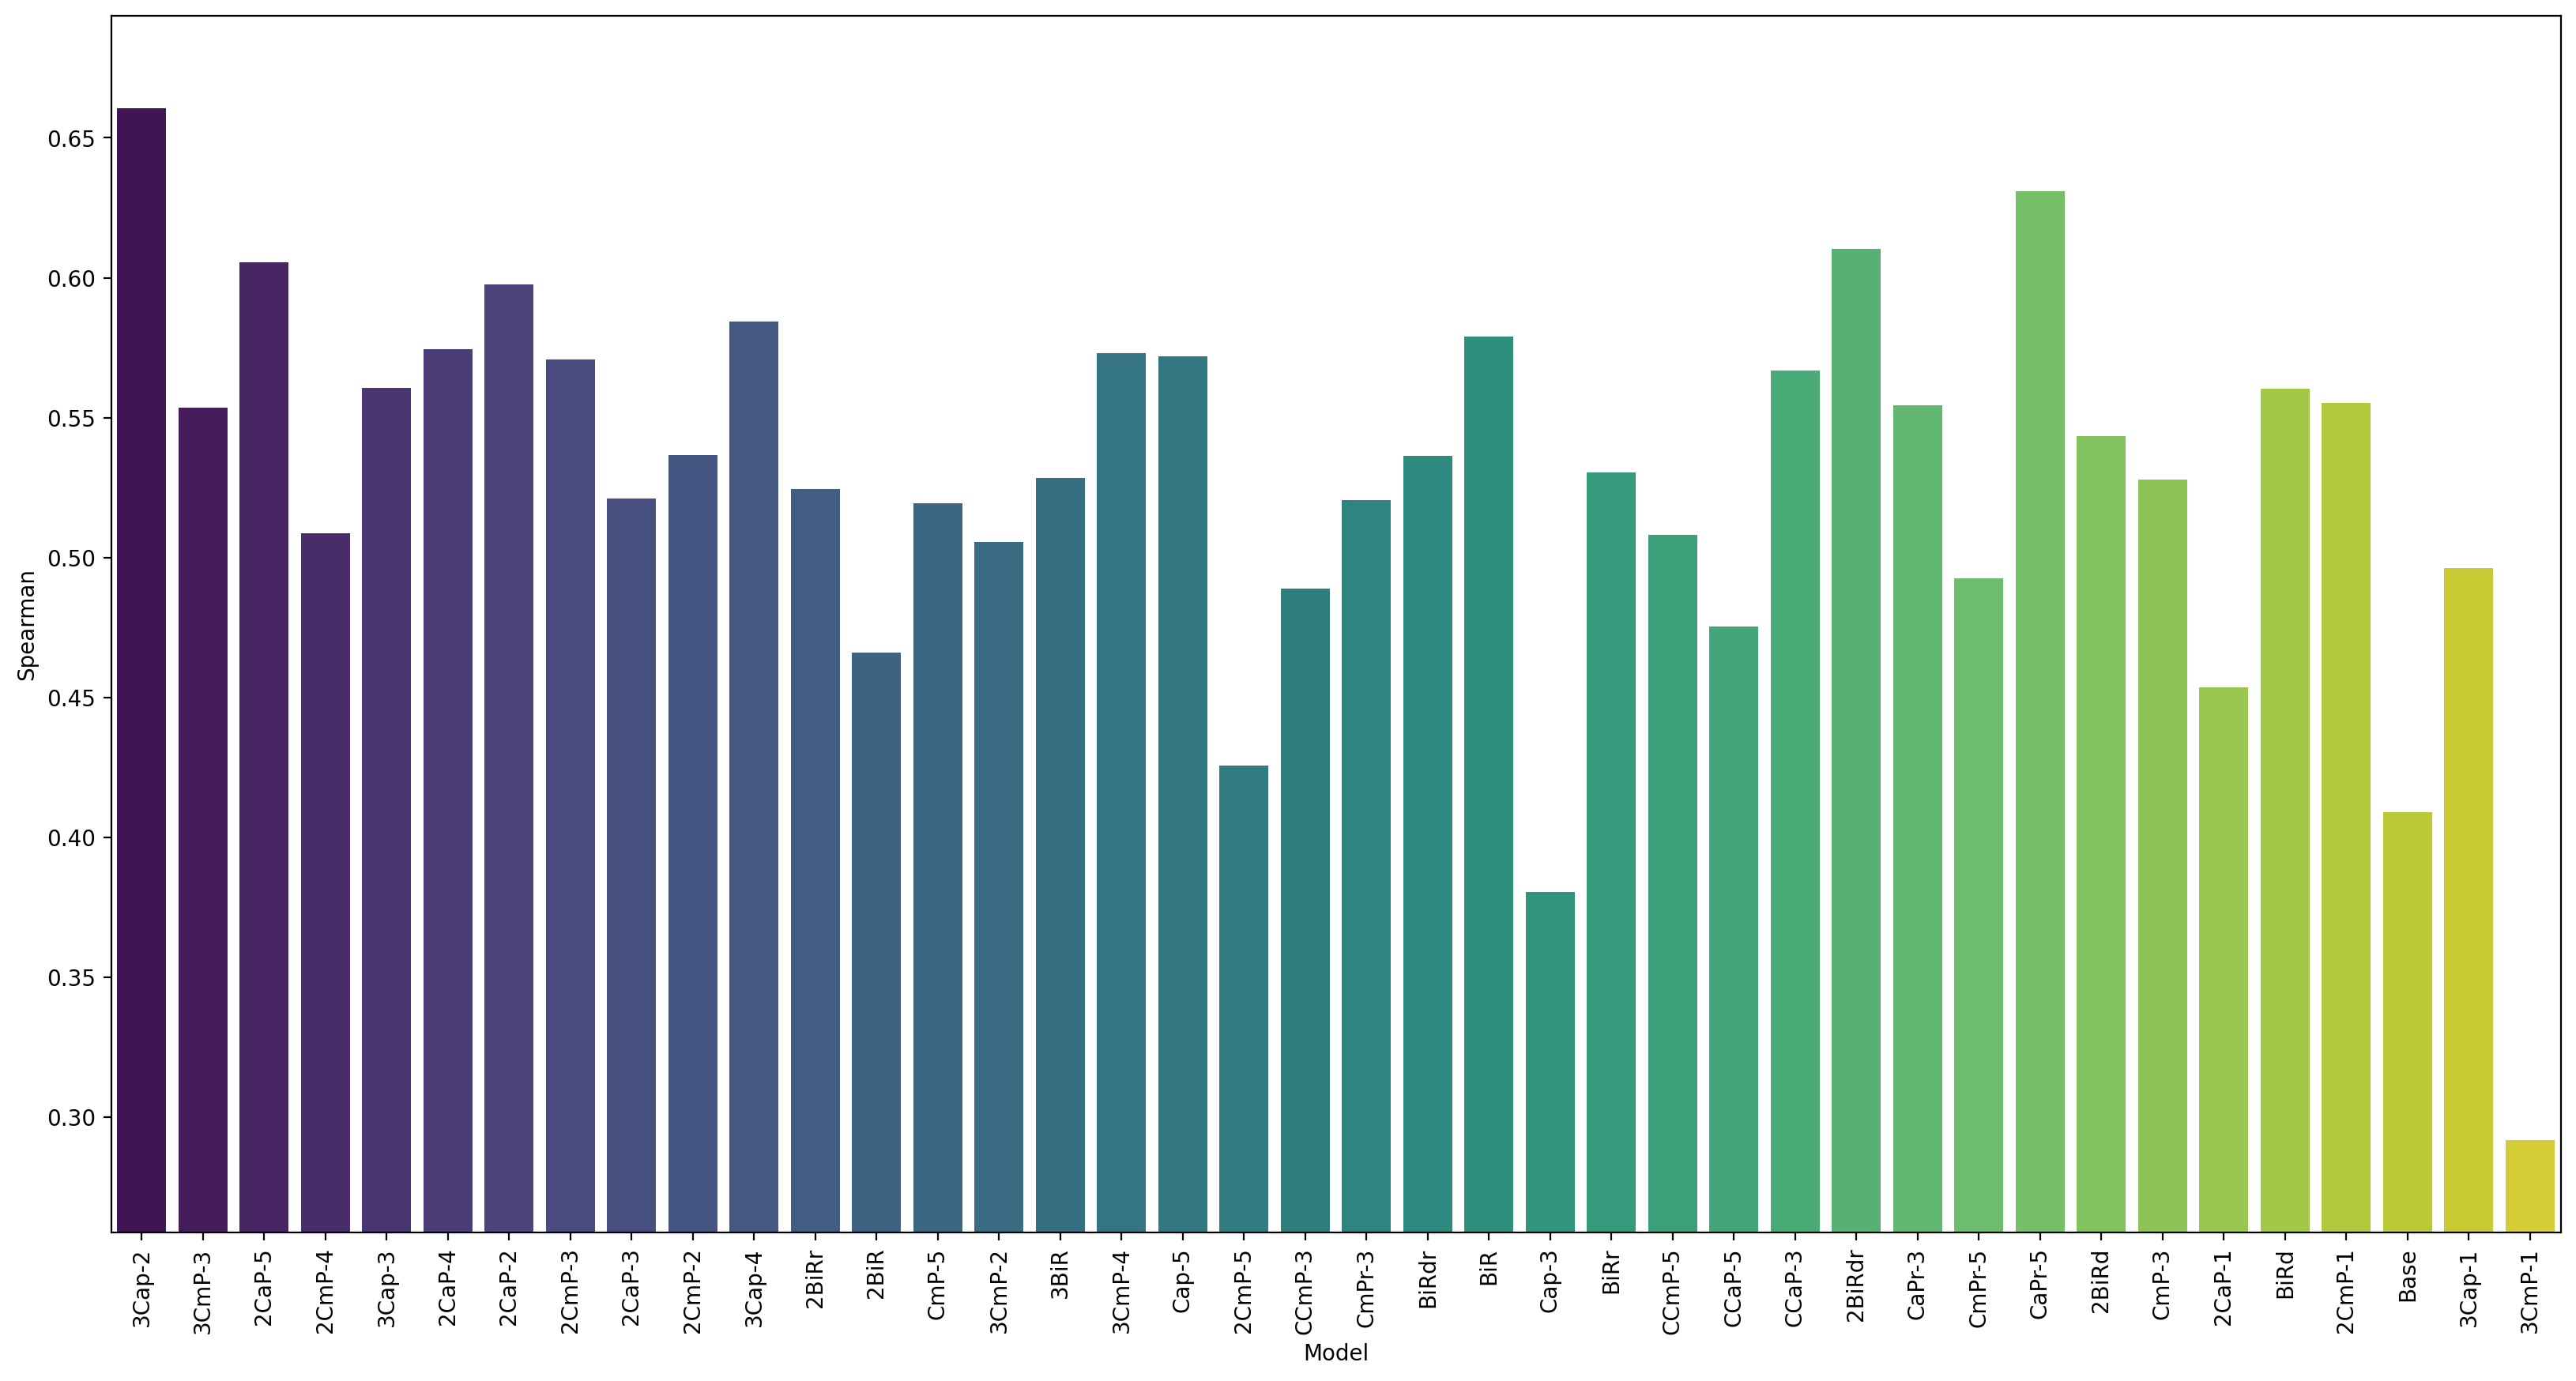

In [7]:
# plate h results #

test_result_actual_model(base_folder, models, alternative_naming, palette, sorted_names, X_h, y_h, output_name='outputs/on-target_plateh.xlsx')